
# STEP 1 — LOAD AND FILTER SINGLE-PRODUCT DATASET

## 1. Objective
Load the original Lake Gardens demand dataset and select only one product, BAB-001 (Pampers Baby Dry Small).

## 2. Theory
The original dataset contains 27,800 records covering 200 products across 139 weeks.

For this experiment, we will perform single-product demand forecasting using the Temporal Fusion Transformer (TFT).

Therefore, we filter the original dataset using its product_id column and retain only BAB-001.

## 3. Why Is This Required?
- Focuses the experiment on one product.
- Removes records belonging to other products.
- Preserves the original historical sales information.
- Creates an independent dataset for single-product preprocessing.

## 4. Selected Product
- Product ID: BAB-001
- Product Name: Pampers Baby Dry Small
- Location: Lake Gardens, Kolkata
- Historical period: January 2024 – August 2026
- Expected records: 139 weeks

## 5. Expected Result
A filtered dataset containing 139 historical weekly records and 89 original columns.

This dataset will be used for further preprocessing and TFT model development.


In [1]:

# STEP 1: LOAD AND FILTER DATASET

import pandas as pd
from pathlib import Path

# Locate original project dataset
possible_paths = [
    Path("../lake_gardens_demand_training_final_clean.xlsx"),
    Path("lake_gardens_demand_training_final_clean.xlsx")
]

DATA_PATH = next(
    (p for p in possible_paths if p.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Original Lake Gardens Excel dataset not found."
    )

# Load original dataset
df = pd.read_excel(DATA_PATH)

# Select one product
selected_product = "BAB-001"

df_single = df[
    df["product_id"] == selected_product
].copy()

# Sort chronologically
df_single = (
    df_single
    .sort_values("week_start_date")
    .reset_index(drop=True)
)

# Display results
print("=" * 60)
print("STEP 1 — SINGLE PRODUCT DATASET")
print("=" * 60)

print("Selected Product:", selected_product)
print("Product Name:", df_single["product_name"].iloc[0])
print("Total Records:", len(df_single))
print("Unique Products:", df_single["product_id"].nunique())
print("Unique Weeks:", df_single["week_id"].nunique())

print("\nDate Range:")
print("Start:", df_single["week_start_date"].min())
print("End:", df_single["week_start_date"].max())

print("\nDataset Shape:", df_single.shape)

# Basic verification
assert len(df_single) == 139
assert df_single["product_id"].nunique() == 1
assert df_single["week_id"].nunique() == 139

print("\nSTEP 1 STATUS: PASSED")

display(df_single.head(10))


STEP 1 — SINGLE PRODUCT DATASET
Selected Product: BAB-001
Product Name: Pampers Baby Dry Small
Total Records: 139
Unique Products: 1
Unique Weeks: 139

Date Range:
Start: 2024-01-01
End: 2026-08-23

Dataset Shape: (139, 89)

STEP 1 STATUS: PASSED


,region_product_week_key,region_id,region_of_kolkata,product_id,product_name,category_name,brand,unit_size,week_id,week_number,...,lag_1_week,lag_2_week,lag_3_week,lag_4_week,lag_8_week,lag_12_week,rolling_mean_4_week,rolling_mean_8_week,rolling_mean_12_week,week_over_week_change
0,KOL-LOC-001_20240101_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,1 kg,W001,1,...,6,6,6,6,6,6,7.0,6.75,7.0,2
1,KOL-LOC-001_20240107_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,50 g,W002,2,...,8,6,6,6,6,6,7.0,6.75,7.0,2
2,KOL-LOC-001_20240114_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,250 g,W003,3,...,8,8,6,6,6,6,7.0,6.75,7.0,0
3,KOL-LOC-001_20240121_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,100 g,W004,4,...,6,8,8,6,6,6,7.0,6.75,7.0,-2
4,KOL-LOC-001_20240128_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,1 kg,W005,5,...,8,6,8,8,6,6,7.5,6.75,7.0,2
5,KOL-LOC-001_20240204_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,1 kg,W006,6,...,6,8,6,8,6,6,7.0,6.75,7.0,-2
6,KOL-LOC-001_20240211_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,250 g,W007,7,...,6,6,8,6,6,6,6.5,6.75,7.0,0
7,KOL-LOC-001_20240218_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,1 kg,W008,8,...,6,6,6,8,6,6,6.5,6.75,7.0,0
8,KOL-LOC-001_20240225_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,50 g,W009,9,...,8,6,6,6,8,6,6.5,7.00,7.0,2
9,KOL-LOC-001_20240303_BAB-001,KOL-LOC-001,Lake Gardens,BAB-001,Pampers Baby Dry Small,Baby Care & Family Care,Pampers,500 g,W010,10,...,6,8,6,6,8,6,6.5,6.75,7.0,-2


Single-Product Data Quality Verification

Before training a TFT model, we must verify that the historical dataset is reliable.

Data quality verification means checking whether the dataset contains missing values, duplicate records, invalid demand values, or inconsistencies in weekly dates.

Even though we have successfully selected one product, we cannot assume that all 139 records are ready for model training.
1. What will we verify?
Check	Purpose
Missing values	Identify unavailable information
Duplicate records	Find repeated weekly observations
Product consistency	Confirm only BAB-001 exists
Weekly continuity	Identify irregular date intervals
Demand validity	Check zero, negative and missing sales
Unit-size consistency	Understand variations in product size
Chronological order	Ensure historical records are sorted

2. Important concepts
Missing values: Data fields without an available value.

Duplicate records: Two or more records representing the same product and week.

Chronological order: Historical observations arranged from oldest to newest.

Data consistency: Information follows the expected structure and rules.

Data validation: Checking whether the dataset meets the requirements for further processing.
3. Why is this important for TFT?
TFT is a time-series forecasting architecture. It needs correctly ordered historical observations to learn demand patterns.

Incorrect dates, duplicate weeks, or invalid sales values can affect training and evaluation.

We will identify problems first instead of immediately deleting or modifying records.
4. Expected result
We expect:
- 139 historical observations.
- Zero duplicate product-week records.
- Zero missing or invalid sales values.
- One unique product.
- Continuous week numbering.
- Any irregular calendar intervals identified.
- Missing optional festival information reported separately.

In [2]:

# STEP 2: SINGLE-PRODUCT DATA QUALITY VERIFICATION

import pandas as pd
import numpy as np

# Create a separate copy for quality verification
df_quality = df_single.copy()

# Convert date columns into datetime format
df_quality["week_start_date"] = pd.to_datetime(
    df_quality["week_start_date"],
    errors="coerce"
)

df_quality["week_end_date"] = pd.to_datetime(
    df_quality["week_end_date"],
    errors="coerce"
)

# --------------------------------------------------
# 1. BASIC DATASET INFORMATION
# --------------------------------------------------

print("=" * 65)
print("STEP 2 — DATA QUALITY VERIFICATION")
print("=" * 65)

print("\n1. DATASET INFORMATION")

print("Total Records:", len(df_quality))
print("Total Columns:", df_quality.shape[1])
print("Unique Products:", df_quality["product_id"].nunique())
print("Unique Weeks:", df_quality["week_id"].nunique())

# --------------------------------------------------
# 2. MISSING VALUE ANALYSIS
# --------------------------------------------------

print("\n2. MISSING VALUE ANALYSIS")

missing_values = df_quality.isnull().sum()

missing_columns = missing_values[missing_values > 0]

if len(missing_columns) > 0:
    print(missing_columns.to_string())
else:
    print("No missing values found.")

print("\nTotal Missing Cells:", missing_values.sum())

# --------------------------------------------------
# 3. DUPLICATE RECORD VERIFICATION
# --------------------------------------------------

print("\n3. DUPLICATE RECORD VERIFICATION")

duplicate_week = df_quality.duplicated(
    subset=["product_id", "week_id"]
).sum()

duplicate_date = df_quality.duplicated(
    subset=["product_id", "week_start_date"]
).sum()

duplicate_key = df_quality[
    "region_product_week_key"
].duplicated().sum()

print("Duplicate Product-Week Records:", duplicate_week)
print("Duplicate Product-Date Records:", duplicate_date)
print("Duplicate Primary Keys:", duplicate_key)

# --------------------------------------------------
# 4. DEMAND VALUE VERIFICATION
# --------------------------------------------------

print("\n4. DEMAND VALUE VERIFICATION")

demand = pd.to_numeric(
    df_quality["units_sold"],
    errors="coerce"
)

print("Missing Demand:", demand.isna().sum())
print("Zero Demand:", (demand == 0).sum())
print("Negative Demand:", (demand < 0).sum())
print("Infinite Demand:", np.isinf(demand).sum())

print("\nDemand Statistics:")
print(demand.describe())

# --------------------------------------------------
# 5. CHRONOLOGICAL ORDER VERIFICATION
# --------------------------------------------------

print("\n5. CHRONOLOGICAL ORDER VERIFICATION")

date_sorted = df_quality[
    "week_start_date"
].is_monotonic_increasing

print("Dates in chronological order:", date_sorted)

# --------------------------------------------------
# 6. WEEKLY CONTINUITY VERIFICATION
# --------------------------------------------------

print("\n6. WEEKLY CONTINUITY VERIFICATION")

date_difference = (
    df_quality["week_start_date"]
    .diff()
    .dt.days
)

irregular_intervals = date_difference[
    date_difference.notna() & date_difference.ne(7)
]

print("Expected Weekly Interval: 7 days")
print("Irregular Date Intervals:", len(irregular_intervals))

if len(irregular_intervals) > 0:
    print("\nIrregular Interval Details:")

    print(
        df_quality.loc[
            irregular_intervals.index,
            ["week_id", "week_start_date"]
        ].assign(
            gap_days=irregular_intervals
        ).to_string(index=False)
    )

# Verify week numbering
expected_week_numbers = list(range(1, len(df_quality) + 1))

week_number_valid = (
    df_quality["week_number"].tolist()
    == expected_week_numbers
)

print("\nSequential Week Numbers:", week_number_valid)

# --------------------------------------------------
# 7. UNIT SIZE ANALYSIS
# --------------------------------------------------

print("\n7. UNIT SIZE ANALYSIS")

print("Unique Unit Sizes:", df_quality["unit_size"].nunique())

print("\nUnit Size Distribution:")
print(df_quality["unit_size"].value_counts().to_string())

# --------------------------------------------------
# 8. FINAL VERIFICATION
# --------------------------------------------------

print("\n" + "=" * 65)
print("FINAL DATA QUALITY SUMMARY")
print("=" * 65)

checks = {
    "Only one product": df_quality["product_id"].nunique() == 1,
    "139 historical records": len(df_quality) == 139,
    "No duplicate product-week records": duplicate_week == 0,
    "No duplicate product-date records": duplicate_date == 0,
    "No missing demand": demand.isna().sum() == 0,
    "No zero or negative demand": (demand <= 0).sum() == 0,
    "No infinite demand": np.isinf(demand).sum() == 0,
    "Chronological order valid": date_sorted,
    "Week numbers sequential": week_number_valid
}

for check, result in checks.items():
    print(f"{'PASS' if result else 'FAIL'}: {check}")

print("\nIrregular calendar intervals:",
      len(irregular_intervals))

print("\nSTEP 2 DATA QUALITY VERIFICATION COMPLETED")


STEP 2 — DATA QUALITY VERIFICATION

1. DATASET INFORMATION
Total Records: 139
Total Columns: 89
Unique Products: 1
Unique Weeks: 139

2. MISSING VALUE ANALYSIS
weather_source__festival_names    114
target_week_festival_names        114

Total Missing Cells: 228

3. DUPLICATE RECORD VERIFICATION
Duplicate Product-Week Records: 0
Duplicate Product-Date Records: 0
Duplicate Primary Keys: 0

4. DEMAND VALUE VERIFICATION
Missing Demand: 0
Zero Demand: 0
Negative Demand: 0
Infinite Demand: 0

Demand Statistics:
count    139.000000
mean       7.115108
std        1.090666
min        5.000000
25%        6.000000
50%        7.000000
75%        8.000000
max        9.000000
Name: units_sold, dtype: float64

5. CHRONOLOGICAL ORDER VERIFICATION
Dates in chronological order: True

6. WEEKLY CONTINUITY VERIFICATION
Expected Weekly Interval: 7 days
Irregular Date Intervals: 1

Irregular Interval Details:
week_id week_start_date  gap_days
   W002      2024-01-07       6.0

Sequential Week Numbers: True


In [3]:

# STEP 2: REMAINING VERIFICATION DETAILS

print("=" * 60)
print("STEP 2 — FINAL VERIFICATION DETAILS")
print("=" * 60)

print("\n1. DEMAND STATISTICS")
print(df_quality["units_sold"].describe())

print("\n2. INFINITE DEMAND")
print(
    np.isinf(
        pd.to_numeric(df_quality["units_sold"])
    ).sum()
)

print("\n3. CHRONOLOGICAL ORDER")
print(df_quality["week_start_date"].is_monotonic_increasing)

print("\n4. SEQUENTIAL WEEK NUMBERS")
print(
    df_quality["week_number"].tolist()
    == list(range(1, len(df_quality) + 1))
)

print("\n5. UNIT SIZE DISTRIBUTION")
print(df_quality["unit_size"].value_counts())

print("\n6. IRREGULAR DATE INTERVALS")
print(irregular_intervals)

print("\nSTEP 2 FINAL DETAILS COMPLETED")


STEP 2 — FINAL VERIFICATION DETAILS

1. DEMAND STATISTICS
count    139.000000
mean       7.115108
std        1.090666
min        5.000000
25%        6.000000
50%        7.000000
75%        8.000000
max        9.000000
Name: units_sold, dtype: float64

2. INFINITE DEMAND
0

3. CHRONOLOGICAL ORDER
True

4. SEQUENTIAL WEEK NUMBERS
True

5. UNIT SIZE DISTRIBUTION
unit_size
250 g    33
1 kg     32
100 g    29
500 g    26
50 g     19
Name: count, dtype: int64

6. IRREGULAR DATE INTERVALS
1    6.0
Name: week_start_date, dtype: float64

STEP 2 FINAL DETAILS COMPLETED



# STEP 3 — HISTORICAL DEMAND ANALYSIS AND FEATURE INVESTIGATION

## 1. Objective

The objective of this step is to analyze the historical demand behavior of BAB-001 and investigate the correctness of its existing time-series features.

We will study weekly demand, demand distribution, historical trends, lag features, rolling averages, and week-over-week changes.

## 2. Historical Demand Analysis

Historical demand analysis helps us understand how product demand changes over time.

We will investigate:

- Average weekly demand.
- Minimum and maximum demand.
- Demand variability.
- Weekly demand trends.
- Demand distribution.

## 3. Lag Features

Lag features represent historical sales values.

Examples:

- lag_1_week: Sales from one week earlier.
- lag_2_week: Sales from two weeks earlier.
- lag_3_week: Sales from three weeks earlier.
- lag_4_week: Sales from four weeks earlier.
- lag_8_week: Sales from eight weeks earlier.
- lag_12_week: Sales from twelve weeks earlier.

Lag features must be calculated using previous observations, not the current week's demand.

## 4. Rolling Mean Features

Rolling mean calculates the average demand over a selected historical window.

Examples:

- rolling_mean_4_week: Average demand over the previous four weeks.
- rolling_mean_8_week: Average demand over the previous eight weeks.
- rolling_mean_12_week: Average demand over the previous twelve weeks.

For forecasting, historical rolling means must exclude the current week's demand.

## 5. Week-over-Week Change

Week-over-week change measures the difference between the current week's demand and the previous week's demand.

Formula:

Change = Current Week Demand - Previous Week Demand

## 6. Why Is This Step Required?

- Understand the demand behavior of BAB-001.
- Identify historical demand patterns.
- Detect incorrect lag calculations.
- Detect current-week information leakage.
- Verify rolling mean calculations.
- Determine which features require reconstruction.

## 7. Visualization Requirements

We will create:

1. Historical weekly demand line chart.
2. Demand distribution histogram.
3. Actual demand versus historical lag comparison.
4. Actual versus stored rolling mean comparison.

## 8. Expected Result

We should understand the demand behavior of BAB-001 and identify which existing features are reliable and which require recalculation before TFT training.


STEP 3.1 — HISTORICAL DEMAND ANALYSIS

PRODUCT INFORMATION
Product ID: BAB-001
Product Name: Pampers Baby Dry Small
Historical Weeks: 139

DEMAND STATISTICS
count    139.000000
mean       7.115108
std        1.090666
min        5.000000
25%        6.000000
50%        7.000000
75%        8.000000
max        9.000000
Name: units_sold, dtype: float64

ADDITIONAL DEMAND INFORMATION
Total Units Sold: 989.0
Unique Demand Values: 5
Most Frequent Demand: 6.0


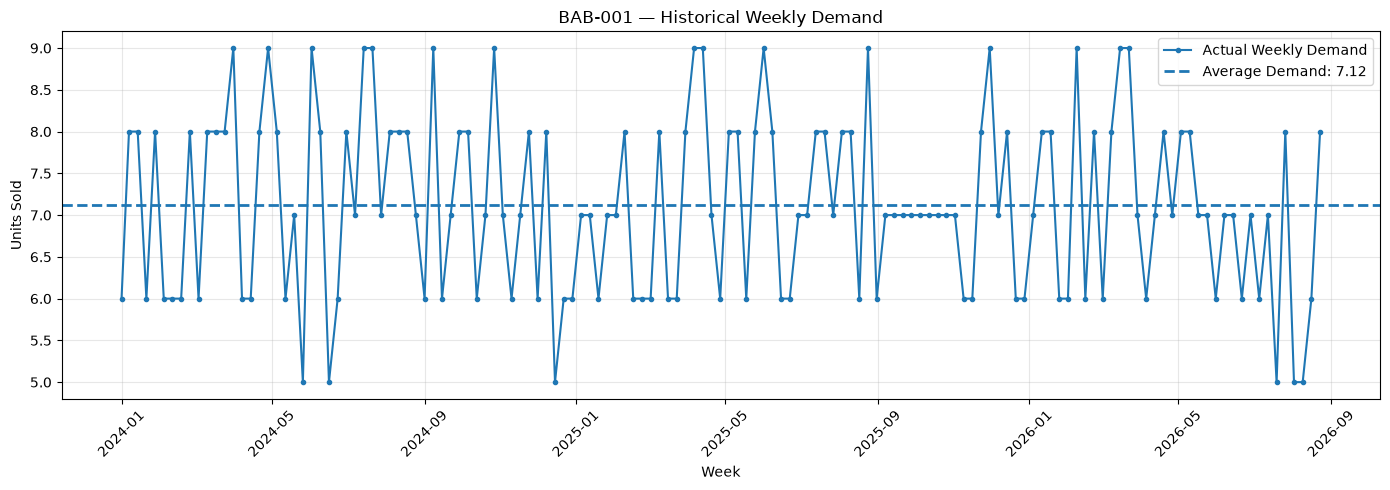

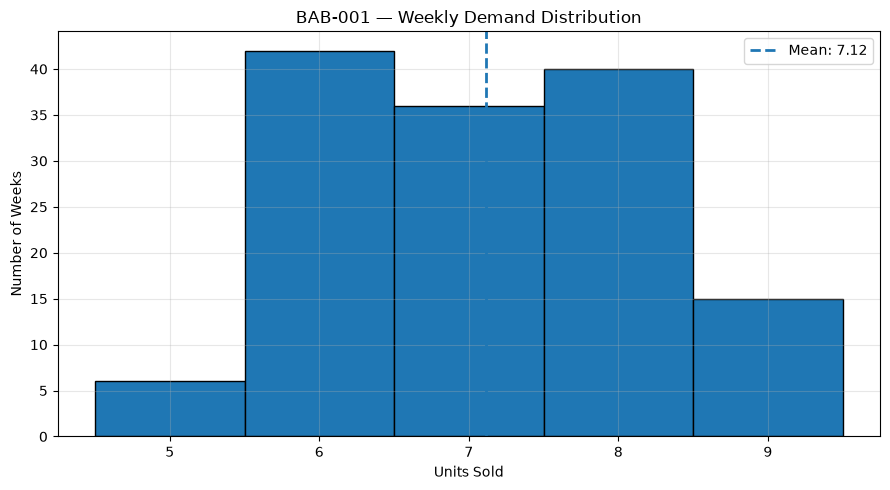

C:\Users\kaifa\AppData\Local\Temp\ipykernel_20696\3378247944.py:113: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


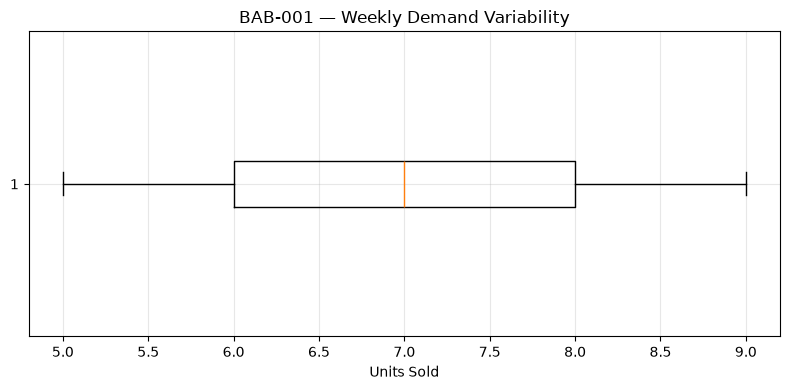


STEP 3.1 COMPLETED


In [4]:

# STEP 3.1 — HISTORICAL DEMAND ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the filtered single-product dataset
df_analysis = df_single.copy()

# Sort observations chronologically
df_analysis["week_start_date"] = pd.to_datetime(
    df_analysis["week_start_date"]
)

df_analysis = (
    df_analysis
    .sort_values("week_start_date")
    .reset_index(drop=True)
)

# Historical demand
demand = df_analysis["units_sold"].astype(float)

# --------------------------------------------------
# 1. DEMAND STATISTICS
# --------------------------------------------------

print("=" * 65)
print("STEP 3.1 — HISTORICAL DEMAND ANALYSIS")
print("=" * 65)

print("\nPRODUCT INFORMATION")
print("Product ID:", df_analysis["product_id"].iloc[0])
print("Product Name:", df_analysis["product_name"].iloc[0])
print("Historical Weeks:", len(df_analysis))

print("\nDEMAND STATISTICS")
print(demand.describe())

print("\nADDITIONAL DEMAND INFORMATION")
print("Total Units Sold:", demand.sum())
print("Unique Demand Values:", demand.nunique())
print("Most Frequent Demand:", demand.mode().iloc[0])

# --------------------------------------------------
# 2. HISTORICAL WEEKLY DEMAND LINE CHART
# --------------------------------------------------

plt.figure(figsize=(14, 5))

plt.plot(
    df_analysis["week_start_date"],
    demand,
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Actual Weekly Demand"
)

plt.axhline(
    demand.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Average Demand: {demand.mean():.2f}"
)

plt.title("BAB-001 — Historical Weekly Demand")
plt.xlabel("Week")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 3. DEMAND DISTRIBUTION HISTOGRAM
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.hist(
    demand,
    bins=np.arange(
        demand.min() - 0.5,
        demand.max() + 1.5,
        1
    ),
    edgecolor="black"
)

plt.axvline(
    demand.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean: {demand.mean():.2f}"
)

plt.title("BAB-001 — Weekly Demand Distribution")
plt.xlabel("Units Sold")
plt.ylabel("Number of Weeks")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. DEMAND BOX PLOT
# --------------------------------------------------

plt.figure(figsize=(8, 4))

plt.boxplot(
    demand,
    vert=False
)

plt.title("BAB-001 — Weekly Demand Variability")
plt.xlabel("Units Sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nSTEP 3.1 COMPLETED")


In [5]:

# STEP 3.2 — LAG FEATURE CORRECTNESS INVESTIGATION

lag_periods = [1, 2, 3, 4, 8, 12]

lag_results = []

for lag in lag_periods:

    column = f"lag_{lag}_week"

    # Correct historical value
    expected_lag = demand.shift(lag)

    stored_lag = pd.to_numeric(
        df_analysis[column],
        errors="coerce"
    )

    valid = expected_lag.notna() & stored_lag.notna()

    matches = np.isclose(
        stored_lag[valid],
        expected_lag[valid]
    ).sum()

    valid_count = valid.sum()

    current_matches = np.isclose(
        stored_lag,
        demand
    ).sum()

    lag_results.append({
        "Lag Feature": column,
        "Valid Historical Rows": valid_count,
        "Correct Historical Matches": matches,
        "Historical Match %": round(
            matches / valid_count * 100, 2
        ) if valid_count else np.nan,
        "Matches Current Demand": current_matches
    })

lag_report = pd.DataFrame(lag_results)

print("=" * 75)
print("LAG FEATURE CORRECTNESS REPORT")
print("=" * 75)

display(lag_report)

# Visual comparison of actual and stored lag values
comparison = df_analysis[
    ["week_id", "units_sold", "lag_1_week"]
].copy()

comparison["Correct Lag 1"] = demand.shift(1)

print("\nFIRST 15 RECORDS — LAG 1 COMPARISON")

display(comparison.head(15))


LAG FEATURE CORRECTNESS REPORT


,Lag Feature,Valid Historical Rows,Correct Historical Matches,Historical Match %,Matches Current Demand
0,lag_1_week,138,39,28.26,139
1,lag_2_week,137,39,28.47,40
2,lag_3_week,136,39,28.68,38
3,lag_4_week,135,38,28.15,37
4,lag_8_week,131,38,29.01,40
5,lag_12_week,127,37,29.13,41



FIRST 15 RECORDS — LAG 1 COMPARISON


,week_id,units_sold,lag_1_week,Correct Lag 1
0,W001,6,6,NaN
1,W002,8,8,6.0
2,W003,8,8,8.0
3,W004,6,6,8.0
4,W005,8,8,6.0
5,W006,6,6,8.0
6,W007,6,6,6.0
7,W008,6,6,6.0
8,W009,8,8,6.0
9,W010,6,6,8.0


In [6]:

# STEP 3.3 — ROLLING MEAN AND WEEK-OVER-WEEK INVESTIGATION

rolling_windows = [4, 8, 12]

rolling_results = []

for window in rolling_windows:

    column = f"rolling_mean_{window}_week"

    stored = pd.to_numeric(
        df_analysis[column],
        errors="coerce"
    )

    # Current-inclusive rolling mean (for diagnosis only)
    current_mean = demand.rolling(
        window=window,
        min_periods=window
    ).mean()

    # Correct historical-only rolling mean
    historical_mean = (
        demand.shift(1)
        .rolling(
            window=window,
            min_periods=window
        )
        .mean()
    )

    current_valid = current_mean.notna() & stored.notna()
    historical_valid = historical_mean.notna() & stored.notna()

    current_matches = np.isclose(
        stored[current_valid],
        current_mean[current_valid]
    ).sum()

    historical_matches = np.isclose(
        stored[historical_valid],
        historical_mean[historical_valid]
    ).sum()

    rolling_results.append({
        "Feature": column,
        "Current Mean Matches": current_matches,
        "Historical Mean Matches": historical_matches,
        "Historical Valid Rows": historical_valid.sum()
    })

rolling_report = pd.DataFrame(rolling_results)

print("=" * 75)
print("ROLLING MEAN CORRECTNESS REPORT")
print("=" * 75)

display(rolling_report)

# --------------------------------------------------
# WEEK-OVER-WEEK CHANGE
# --------------------------------------------------

expected_change = demand.diff()

stored_change = pd.to_numeric(
    df_analysis["week_over_week_change"],
    errors="coerce"
)

valid_change = expected_change.notna() & stored_change.notna()

wow_matches = np.isclose(
    stored_change[valid_change],
    expected_change[valid_change]
).sum()

print("\nWEEK-OVER-WEEK CHANGE VERIFICATION")

print("Valid Historical Comparisons:", valid_change.sum())
print("Correct Matches:", wow_matches)

print(
    "Match Percentage:",
    round(wow_matches / valid_change.sum() * 100, 2),
    "%"
)

wow_comparison = pd.DataFrame({
    "Week": df_analysis["week_id"],
    "Actual Demand": demand,
    "Stored Change": stored_change,
    "Correct Historical Change": expected_change
})

display(wow_comparison.head(15))

print("\nSTEP 3.3 COMPLETED")


ROLLING MEAN CORRECTNESS REPORT


,Feature,Current Mean Matches,Historical Mean Matches,Historical Valid Rows
0,rolling_mean_4_week,136,38,135
1,rolling_mean_8_week,132,42,131
2,rolling_mean_12_week,128,29,127



WEEK-OVER-WEEK CHANGE VERIFICATION
Valid Historical Comparisons: 138
Correct Matches: 138
Match Percentage: 100.0 %


,Week,Actual Demand,Stored Change,Correct Historical Change
0,W001,6.0,2,NaN
1,W002,8.0,2,2.0
2,W003,8.0,0,0.0
3,W004,6.0,-2,-2.0
4,W005,8.0,2,2.0
5,W006,6.0,-2,-2.0
6,W007,6.0,0,0.0
7,W008,6.0,0,0.0
8,W009,8.0,2,2.0
9,W010,6.0,-2,-2.0



STEP 3.3 COMPLETED


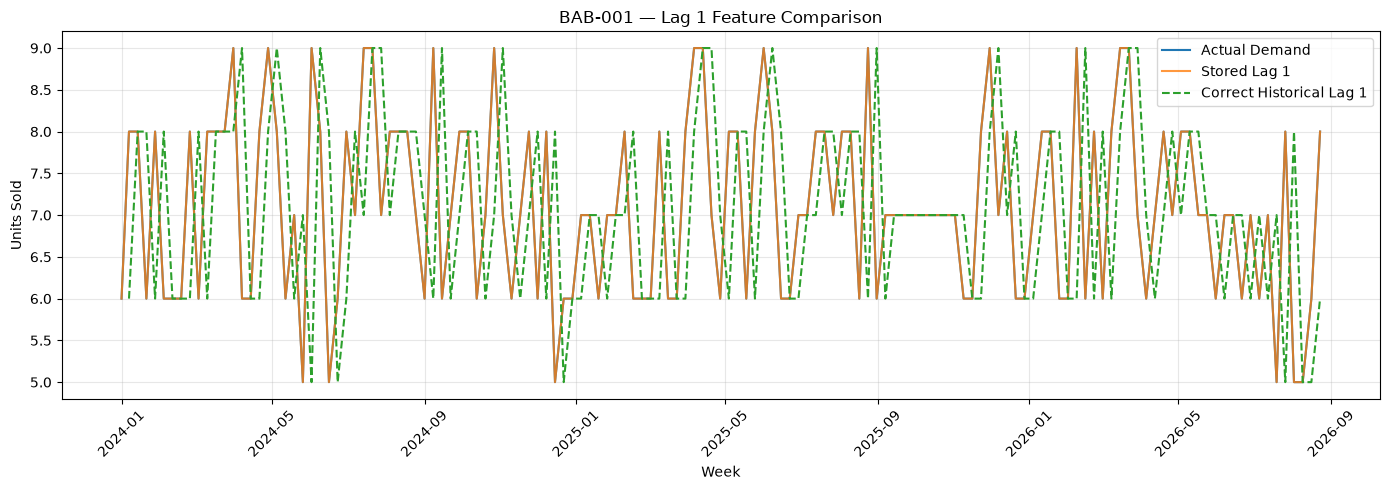

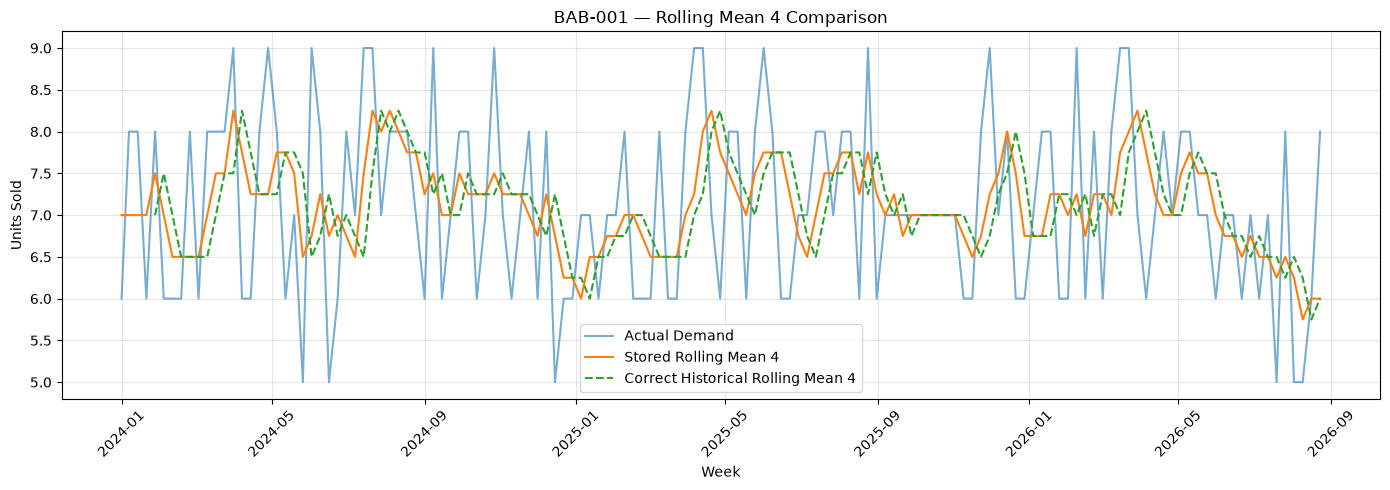

STEP 3 VISUAL INVESTIGATION COMPLETED


In [7]:

# STEP 3.4 — FEATURE COMPARISON VISUALIZATIONS

# 1. Actual demand vs stored lag 1 vs correct lag 1

plt.figure(figsize=(14, 5))

plt.plot(
    df_analysis["week_start_date"],
    demand,
    label="Actual Demand",
    linewidth=1.5
)

plt.plot(
    df_analysis["week_start_date"],
    df_analysis["lag_1_week"],
    label="Stored Lag 1",
    alpha=0.8
)

plt.plot(
    df_analysis["week_start_date"],
    demand.shift(1),
    label="Correct Historical Lag 1",
    linestyle="--"
)

plt.title("BAB-001 — Lag 1 Feature Comparison")
plt.xlabel("Week")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Stored rolling mean vs correct historical rolling mean

plt.figure(figsize=(14, 5))

plt.plot(
    df_analysis["week_start_date"],
    demand,
    label="Actual Demand",
    alpha=0.6
)

plt.plot(
    df_analysis["week_start_date"],
    df_analysis["rolling_mean_4_week"],
    label="Stored Rolling Mean 4"
)

correct_rolling_4 = (
    demand.shift(1)
    .rolling(window=4, min_periods=4)
    .mean()
)

plt.plot(
    df_analysis["week_start_date"],
    correct_rolling_4,
    label="Correct Historical Rolling Mean 4",
    linestyle="--"
)

plt.title("BAB-001 — Rolling Mean 4 Comparison")
plt.xlabel("Week")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("STEP 3 VISUAL INVESTIGATION COMPLETED")


Historical Feature Reconstruction and Preprocessing

Important preprocessing concepts
Before writing code, understand these three operations.
Operation	Formula	Purpose
Lag	demand.shift(k)	Retrieve previous week's sales
Rolling mean	demand.shift(1).rolling(k).mean()	Average previous k weeks
WoW change	demand.diff()	Difference from previous week

For example, suppose the historical demand is:
Week	Sales
W001	6
W002	8
W003	8
W004	6
W005	8

For W005:
- Lag 1 = 6
- Lag 2 = 8
- Lag 3 = 8
- Lag 4 = 6
- Rolling mean 4 = (6 + 8 + 8 + 6) / 4 = 7

In [8]:

# STEP 4.1 — RECONSTRUCT HISTORICAL FEATURES

import pandas as pd
import numpy as np

# Preserve the original filtered dataset
df_single_processed = df_single.copy()

# Sort chronologically
df_single_processed["week_start_date"] = pd.to_datetime(
    df_single_processed["week_start_date"]
)

df_single_processed = (
    df_single_processed
    .sort_values("week_start_date")
    .reset_index(drop=True)
)

# Ensure demand is numeric
df_single_processed["units_sold"] = pd.to_numeric(
    df_single_processed["units_sold"],
    errors="coerce"
)

# Historical demand series
demand = df_single_processed["units_sold"]

print("=" * 65)
print("STEP 4.1 — HISTORICAL FEATURE RECONSTRUCTION")
print("=" * 65)

# --------------------------------------------------
# 1. RECONSTRUCT LAG FEATURES
# --------------------------------------------------

lag_periods = [1, 2, 3, 4, 8, 12]

for lag in lag_periods:

    column = f"lag_{lag}_week"

    df_single_processed[column] = demand.shift(lag)

# --------------------------------------------------
# 2. RECONSTRUCT ROLLING MEAN FEATURES
# --------------------------------------------------

rolling_windows = [4, 8, 12]

for window in rolling_windows:

    column = f"rolling_mean_{window}_week"

    df_single_processed[column] = (
        demand.shift(1)
        .rolling(
            window=window,
            min_periods=window
        )
        .mean()
    )

# --------------------------------------------------
# 3. RECONSTRUCT WEEK-OVER-WEEK CHANGE
# --------------------------------------------------

df_single_processed["week_over_week_change"] = (
    demand.diff()
)

# --------------------------------------------------
# 4. DISPLAY RESULTS
# --------------------------------------------------

reconstructed_columns = [
    "week_id",
    "units_sold",
    "lag_1_week",
    "lag_2_week",
    "lag_3_week",
    "lag_4_week",
    "lag_8_week",
    "lag_12_week",
    "rolling_mean_4_week",
    "rolling_mean_8_week",
    "rolling_mean_12_week",
    "week_over_week_change"
]

print("\nRECONSTRUCTED HISTORICAL FEATURES")

display(
    df_single_processed[
        reconstructed_columns
    ].head(15)
)

print("\nOriginal Dataset Shape:", df_single.shape)
print("Processed Dataset Shape:", df_single_processed.shape)

print("\nSTEP 4.1 COMPLETED")


STEP 4.1 — HISTORICAL FEATURE RECONSTRUCTION

RECONSTRUCTED HISTORICAL FEATURES


,week_id,units_sold,lag_1_week,lag_2_week,lag_3_week,lag_4_week,lag_8_week,lag_12_week,rolling_mean_4_week,rolling_mean_8_week,rolling_mean_12_week,week_over_week_change
0,W001,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,W002,8,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0
2,W003,8,8.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,W004,6,8.0,8.0,6.0,NaN,NaN,NaN,NaN,NaN,NaN,-2.0
4,W005,8,6.0,8.0,8.0,6.0,NaN,NaN,7.00,NaN,NaN,2.0
5,W006,6,8.0,6.0,8.0,8.0,NaN,NaN,7.50,NaN,NaN,-2.0
6,W007,6,6.0,8.0,6.0,8.0,NaN,NaN,7.00,NaN,NaN,0.0
7,W008,6,6.0,6.0,8.0,6.0,NaN,NaN,6.50,NaN,NaN,0.0
8,W009,8,6.0,6.0,6.0,8.0,6.0,NaN,6.50,6.750,NaN,2.0
9,W010,6,8.0,6.0,6.0,6.0,8.0,NaN,6.50,7.000,NaN,-2.0



Original Dataset Shape: (139, 89)
Processed Dataset Shape: (139, 89)

STEP 4.1 COMPLETED


In [9]:

# STEP 4.2 — VERIFY RECONSTRUCTED FEATURES

print("=" * 65)
print("STEP 4.2 — RECONSTRUCTED FEATURE VERIFICATION")
print("=" * 65)

verification_results = []

# Verify lag features
for lag in [1, 2, 3, 4, 8, 12]:

    column = f"lag_{lag}_week"

    expected = demand.shift(lag)

    actual = df_single_processed[column]

    valid = expected.notna() & actual.notna()

    correct = np.isclose(
        expected[valid],
        actual[valid]
    ).all()

    verification_results.append({
        "Feature": column,
        "Expected Missing": expected.isna().sum(),
        "Actual Missing": actual.isna().sum(),
        "Verification": "PASS" if correct else "FAIL"
    })

# Verify rolling means
for window in [4, 8, 12]:

    column = f"rolling_mean_{window}_week"

    expected = (
        demand.shift(1)
        .rolling(window, min_periods=window)
        .mean()
    )

    actual = df_single_processed[column]

    valid = expected.notna() & actual.notna()

    correct = np.allclose(
        expected[valid],
        actual[valid]
    )

    verification_results.append({
        "Feature": column,
        "Expected Missing": expected.isna().sum(),
        "Actual Missing": actual.isna().sum(),
        "Verification": "PASS" if correct else "FAIL"
    })

# Verify week-over-week change
expected_change = demand.diff()

actual_change = df_single_processed[
    "week_over_week_change"
]

valid = expected_change.notna() & actual_change.notna()

change_correct = np.allclose(
    expected_change[valid],
    actual_change[valid]
)

verification_results.append({
    "Feature": "week_over_week_change",
    "Expected Missing": expected_change.isna().sum(),
    "Actual Missing": actual_change.isna().sum(),
    "Verification": "PASS" if change_correct else "FAIL"
})

verification_report = pd.DataFrame(
    verification_results
)

display(verification_report)

print("\nAll Features Correct:",
      verification_report["Verification"].eq("PASS").all())

print("\nSTEP 4.2 COMPLETED")


STEP 4.2 — RECONSTRUCTED FEATURE VERIFICATION


,Feature,Expected Missing,Actual Missing,Verification
0,lag_1_week,1,1,PASS
1,lag_2_week,2,2,PASS
2,lag_3_week,3,3,PASS
3,lag_4_week,4,4,PASS
4,lag_8_week,8,8,PASS
5,lag_12_week,12,12,PASS
6,rolling_mean_4_week,4,4,PASS
7,rolling_mean_8_week,8,8,PASS
8,rolling_mean_12_week,12,12,PASS
9,week_over_week_change,1,1,PASS



All Features Correct: True

STEP 4.2 COMPLETED


In [10]:

# STEP 4.3 — ORIGINAL VS RECONSTRUCTED FEATURE COMPARISON

original_features = (
    df_single
    .sort_values("week_start_date")
    .reset_index(drop=True)
)

comparison_results = []

# Compare lag features
for lag in [1, 2, 3, 4, 8, 12]:

    column = f"lag_{lag}_week"

    old = pd.to_numeric(
        original_features[column],
        errors="coerce"
    )

    new = df_single_processed[column]

    valid = old.notna() & new.notna()

    matches = np.isclose(
        old[valid],
        new[valid]
    ).sum()

    comparison_results.append({
        "Feature": column,
        "Comparable Rows": valid.sum(),
        "Matching Old Values": matches,
        "Different Old Values": valid.sum() - matches
    })

# Compare rolling mean features
for window in [4, 8, 12]:

    column = f"rolling_mean_{window}_week"

    old = pd.to_numeric(
        original_features[column],
        errors="coerce"
    )

    new = df_single_processed[column]

    valid = old.notna() & new.notna()

    matches = np.isclose(
        old[valid],
        new[valid]
    ).sum()

    comparison_results.append({
        "Feature": column,
        "Comparable Rows": valid.sum(),
        "Matching Old Values": matches,
        "Different Old Values": valid.sum() - matches
    })

comparison_report = pd.DataFrame(comparison_results)

print("=" * 75)
print("ORIGINAL VS RECONSTRUCTED FEATURES")
print("=" * 75)

display(comparison_report)

print("\nComparison completed.")


ORIGINAL VS RECONSTRUCTED FEATURES


,Feature,Comparable Rows,Matching Old Values,Different Old Values
0,lag_1_week,138,39,99
1,lag_2_week,137,39,98
2,lag_3_week,136,39,97
3,lag_4_week,135,38,97
4,lag_8_week,131,38,93
5,lag_12_week,127,37,90
6,rolling_mean_4_week,135,38,97
7,rolling_mean_8_week,131,42,89
8,rolling_mean_12_week,127,29,98



Comparison completed.


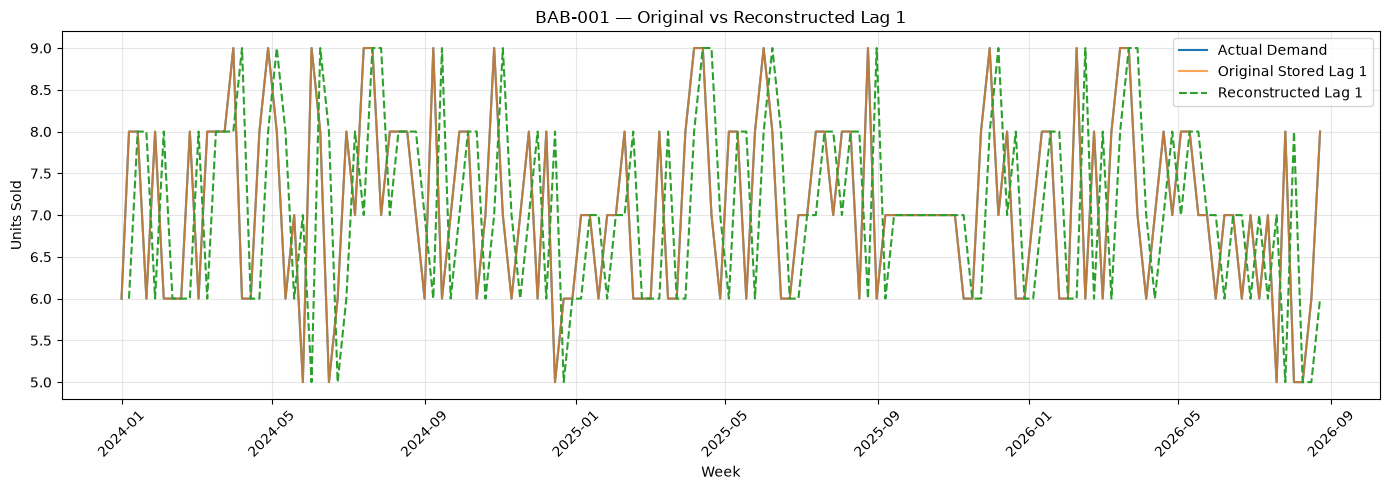

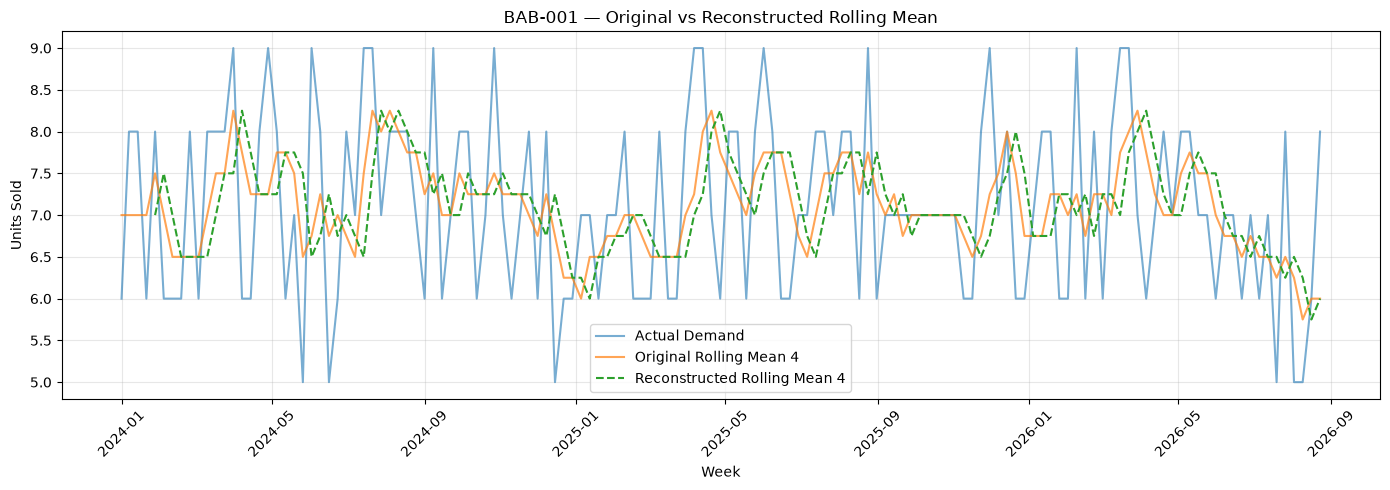

STEP 4 VISUALIZATIONS COMPLETED


In [11]:

# STEP 4.4 — FEATURE RECONSTRUCTION VISUALIZATIONS

import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. LAG 1 COMPARISON
# --------------------------------------------------

plt.figure(figsize=(14, 5))

plt.plot(
    df_single_processed["week_start_date"],
    df_single_processed["units_sold"],
    label="Actual Demand",
    linewidth=1.5
)

plt.plot(
    df_single_processed["week_start_date"],
    original_features["lag_1_week"],
    label="Original Stored Lag 1",
    alpha=0.7
)

plt.plot(
    df_single_processed["week_start_date"],
    df_single_processed["lag_1_week"],
    label="Reconstructed Lag 1",
    linestyle="--"
)

plt.title("BAB-001 — Original vs Reconstructed Lag 1")
plt.xlabel("Week")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 2. ROLLING MEAN COMPARISON
# --------------------------------------------------

plt.figure(figsize=(14, 5))

plt.plot(
    df_single_processed["week_start_date"],
    df_single_processed["units_sold"],
    label="Actual Demand",
    alpha=0.6
)

plt.plot(
    df_single_processed["week_start_date"],
    original_features["rolling_mean_4_week"],
    label="Original Rolling Mean 4",
    alpha=0.7
)

plt.plot(
    df_single_processed["week_start_date"],
    df_single_processed["rolling_mean_4_week"],
    label="Reconstructed Rolling Mean 4",
    linestyle="--"
)

plt.title("BAB-001 — Original vs Reconstructed Rolling Mean")
plt.xlabel("Week")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("STEP 4 VISUALIZATIONS COMPLETED")


Feature Selection and Final Preprocessing

A feature is an input that helps a model learn patterns and make predictions.

For this experiment, we will start with a minimal TFT feature set:
Column	Purpose	Decision
product_id	Identifies the product/group	Keep
time_idx	Identifies the weekly time sequence	Create
units_sold	Historical demand to forecast	Keep as target

Why are we starting with only these columns?
1. We have only 139 weekly records for one product.
2. category_name and brand are constant for this single product, so they provide no variation for learning.
3. TFT already learns historical patterns from the encoder sequence. We do not need to feed it the reconstructed lag and rolling columns as additional inputs.
4. Some weather and festival fields have missing values. We should not add them without proving they are reliable and useful.
5. We want to avoid unnecessary features and reduce the risk of overfitting

In [12]:
# STEP 5.2 — Audit candidate features

import pandas as pd
import numpy as np

# Check that Step 4 output exists
if "df_single_processed" not in globals():
    raise NameError(
        "df_single_processed not found. "
        "Please complete Step 4 first."
    )

df_step5 = df_single_processed.copy()

# Sort data chronologically
df_step5 = df_step5.sort_values(
    "week_start_date"
).reset_index(drop=True)

# Candidate columns to investigate
candidate_features = [
    "units_sold",
    "category_name",
    "brand",
    "season",
    "holiday_flag",
    "temperature_c",
    "rainfall_mm",
    "weather_missing",
    "stockout_flag",
    "lag_1_week",
    "lag_2_week",
    "lag_3_week",
    "lag_4_week",
    "lag_8_week",
    "lag_12_week",
    "rolling_mean_4_week",
    "rolling_mean_8_week",
    "rolling_mean_12_week",
    "week_over_week_change"
]

available_features = [
    col for col in candidate_features
    if col in df_step5.columns
]

feature_audit = pd.DataFrame({
    "Feature": available_features,
    "Missing_Values": [
        df_step5[col].isna().sum()
        for col in available_features
    ],
    "Unique_Values": [
        df_step5[col].nunique(dropna=True)
        for col in available_features
    ],
    "Data_Type": [
        str(df_step5[col].dtype)
        for col in available_features
    ]
})

print("=" * 65)
print("STEP 5.2 — CANDIDATE FEATURE AUDIT")
print("=" * 65)

print(feature_audit.to_string(index=False))

STEP 5.2 — CANDIDATE FEATURE AUDIT
              Feature  Missing_Values  Unique_Values Data_Type
           units_sold               0              5     int64
        category_name               0              1       str
                brand               0              1       str
               season               0              5       str
         holiday_flag               0              2      bool
        temperature_c               0             94   float64
          rainfall_mm               0            119   float64
        stockout_flag               0              2      bool
           lag_1_week               1              5   float64
           lag_2_week               2              5   float64
           lag_3_week               3              5   float64
           lag_4_week               4              5   float64
           lag_8_week               8              5   float64
          lag_12_week              12              5   float64
  rolling_mean_4_wee

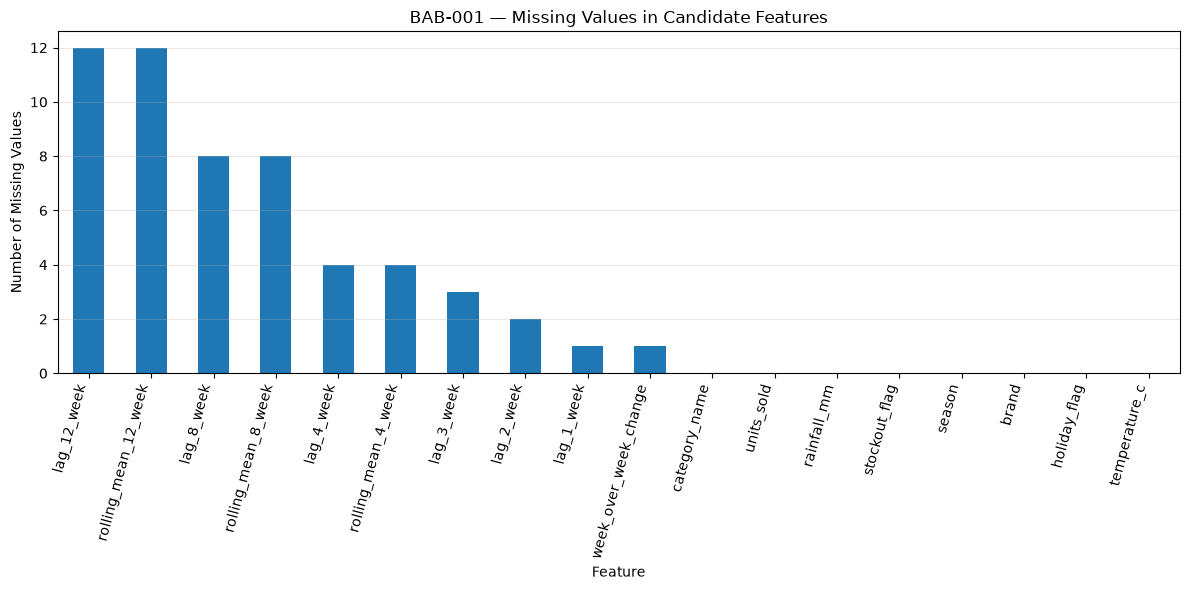

In [13]:
# STEP 5.3 — Missing-value visualization

import matplotlib.pyplot as plt

missing_counts = (
    feature_audit
    .set_index("Feature")["Missing_Values"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

missing_counts.plot(kind="bar")

plt.title("BAB-001 — Missing Values in Candidate Features")
plt.xlabel("Feature")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=75, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# STEP 5.4 — Final feature selection

# Create chronological time index
df_step5["time_idx"] = np.arange(len(df_step5))

# Select final model columns
selected_columns = [
    "product_id",
    "time_idx",
    "units_sold"
]

df_tft_single = df_step5[selected_columns].copy()

# Ensure correct data types
df_tft_single["product_id"] = (
    df_tft_single["product_id"].astype(str)
)

df_tft_single["time_idx"] = (
    pd.to_numeric(
        df_tft_single["time_idx"],
        errors="raise"
    ).astype(int)
)

df_tft_single["units_sold"] = (
    pd.to_numeric(
        df_tft_single["units_sold"],
        errors="raise"
    )
)

# Final verification
print("=" * 65)
print("STEP 5.4 — FINAL TFT DATASET")
print("=" * 65)

print("Dataset Shape:", df_tft_single.shape)
print("Selected Product:", df_tft_single["product_id"].unique())
print("Unique Products:", df_tft_single["product_id"].nunique())

print(
    "Time Index:",
    df_tft_single["time_idx"].min(),
    "to",
    df_tft_single["time_idx"].max()
)

print("Missing Values:", df_tft_single.isna().sum().sum())
print("Duplicate Time Index:", df_tft_single["time_idx"].duplicated().sum())
print("Negative Demand:", (df_tft_single["units_sold"] < 0).sum())

print("\nFirst 10 Records:")
display(df_tft_single.head(10))

print("\nLast 5 Records:")
display(df_tft_single.tail(5))

STEP 5.4 — FINAL TFT DATASET
Dataset Shape: (139, 3)
Selected Product: <StringArray>
['BAB-001']
Length: 1, dtype: str
Unique Products: 1
Time Index: 0 to 138
Missing Values: 0
Duplicate Time Index: 0
Negative Demand: 0

First 10 Records:


,product_id,time_idx,units_sold
0,BAB-001,0,6
1,BAB-001,1,8
2,BAB-001,2,8
3,BAB-001,3,6
4,BAB-001,4,8
5,BAB-001,5,6
6,BAB-001,6,6
7,BAB-001,7,6
8,BAB-001,8,8
9,BAB-001,9,6



Last 5 Records:


,product_id,time_idx,units_sold
134,BAB-001,134,8
135,BAB-001,135,5
136,BAB-001,136,5
137,BAB-001,137,6
138,BAB-001,138,8


Chronological Train / Validation / Test Split (70% / 15% / 15%)

Dataset	Percentage	Purpose
Training	70%	Model learns historical demand patterns
Validation	15%	We check model performance during training and tune it
Testing	15%	We evaluate the final model on unseen weeks

For 139 records, our split will be:
BAB-001 — Weekly data division





Training

97
Weeks 1–97


Validation

21
Weeks 98–118


Testing

21
Weeks 119–139



Total records
139


- Training: the model learns from the earliest 97 weeks.
- Validation: helps us decide whether the model is learning properly.
- Testing: gives us a final, independent evaluation.


In [15]:
# STEP 6.2 — Chronological Train / Validation / Test Split

import pandas as pd
import numpy as np

# Verify the Step 5 dataset
if "df_tft_single" not in globals():
    raise NameError(
        "df_tft_single not found. Please complete Step 5 first."
    )

# Copy and sort chronologically
df_split = df_tft_single.copy()
df_split = df_split.sort_values("time_idx").reset_index(drop=True)

# Verify the expected dataset
assert len(df_split) == 139, "Expected 139 weekly records."
assert df_split["product_id"].nunique() == 1
assert df_split["time_idx"].is_monotonic_increasing
assert df_split["units_sold"].notna().all()

# Calculate split boundaries
total_records = len(df_split)

train_end = int(total_records * 0.70)
validation_end = train_end + int(total_records * 0.15)

# Chronological splitting
train_df = df_split.iloc[:train_end].copy()

validation_df = df_split.iloc[
    train_end:validation_end
].copy()

test_df = df_split.iloc[validation_end:].copy()

# Add split labels for visualization
df_split["dataset_split"] = (
    ["Training"] * len(train_df)
    + ["Validation"] * len(validation_df)
    + ["Testing"] * len(test_df)
)

# Display results
print("=" * 65)
print("STEP 6 — CHRONOLOGICAL DATA SPLITTING")
print("=" * 65)

print("Total Records:", total_records)

print("\nTRAINING DATA")
print("Records:", len(train_df))
print("Time Index:", train_df["time_idx"].min(),
      "to", train_df["time_idx"].max())

print("\nVALIDATION DATA")
print("Records:", len(validation_df))
print("Time Index:", validation_df["time_idx"].min(),
      "to", validation_df["time_idx"].max())

print("\nTEST DATA")
print("Records:", len(test_df))
print("Time Index:", test_df["time_idx"].min(),
      "to", test_df["time_idx"].max())

print("\nSPLIT PERCENTAGES")
for name, data in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Testing", test_df)
]:
    percentage = len(data) / total_records * 100
    print(f"{name}: {percentage:.2f}%")

print("\nTotal after splitting:",
      len(train_df) + len(validation_df) + len(test_df))

print("\nSTEP 6 STATUS: SPLIT CREATED")

STEP 6 — CHRONOLOGICAL DATA SPLITTING
Total Records: 139

TRAINING DATA
Records: 97
Time Index: 0 to 96

VALIDATION DATA
Records: 20
Time Index: 97 to 116

TEST DATA
Records: 22
Time Index: 117 to 138

SPLIT PERCENTAGES
Training: 69.78%
Validation: 14.39%
Testing: 15.83%

Total after splitting: 139

STEP 6 STATUS: SPLIT CREATED


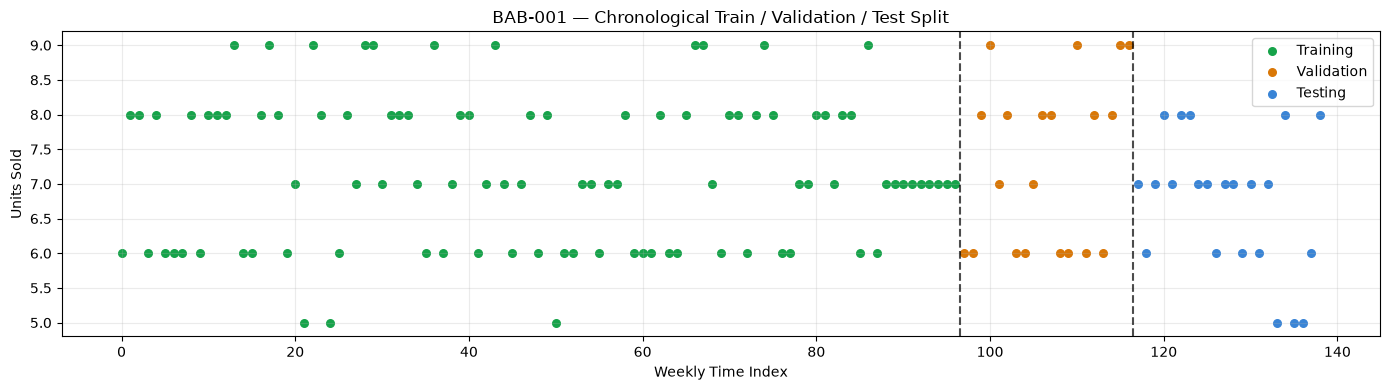

In [16]:
# STEP 6.3 — Train / Validation / Test Timeline

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 4))

split_colors = {
    "Training": "#16A34A",
    "Validation": "#D97706",
    "Testing": "#3984D6"
}

for split_name, split_data in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Testing", test_df)
]:
    plt.scatter(
        split_data["time_idx"],
        split_data["units_sold"],
        label=split_name,
        color=split_colors[split_name],
        s=30
    )

plt.axvline(
    train_end - 0.5,
    linestyle="--",
    color="black",
    alpha=0.7
)

plt.axvline(
    validation_end - 0.5,
    linestyle="--",
    color="black",
    alpha=0.7
)

plt.title("BAB-001 — Chronological Train / Validation / Test Split")
plt.xlabel("Weekly Time Index")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [17]:
# STEP 6.4 — Final split verification

checks = {
    "Training has 97 records": len(train_df) == 97,
    "Validation has 21 records": len(validation_df) == 21,
    "Testing has 21 records": len(test_df) == 21,

    "Training ends before validation":
        train_df["time_idx"].max()
        < validation_df["time_idx"].min(),

    "Validation ends before testing":
        validation_df["time_idx"].max()
        < test_df["time_idx"].min(),

    "All 139 records preserved":
        len(train_df) + len(validation_df) + len(test_df) == 139,

    "No missing training demand":
        train_df["units_sold"].notna().all(),

    "No missing validation demand":
        validation_df["units_sold"].notna().all(),

    "No missing test demand":
        test_df["units_sold"].notna().all()
}

print("=" * 65)
print("STEP 6 — FINAL VERIFICATION")
print("=" * 65)

for check, result in checks.items():
    print(f"{'PASS' if result else 'FAIL'}: {check}")

print("\nOVERALL STATUS:",
      "PASSED" if all(checks.values()) else "FAILED")

STEP 6 — FINAL VERIFICATION
PASS: Training has 97 records
FAIL: Validation has 21 records
FAIL: Testing has 21 records
PASS: Training ends before validation
PASS: Validation ends before testing
PASS: All 139 records preserved
PASS: No missing training demand
PASS: No missing validation demand
PASS: No missing test demand

OVERALL STATUS: FAILED


TFT TimeSeriesDataSet Preparation

In this step, we will convert your BAB-001 weekly demand data into the format required by the Temporal Fusion Transformer (TFT).

This is an important step: a normal Pandas DataFrame is not enough for TFT training. We need PyTorch Forecasting's TimeSeriesDataSet to organize historical observations into encoder and prediction sequences.

We will keep your existing 200-product TFT project unchanged and work only with the single-product experiment.
7.1 — Theory: How TFT reads the data
TFT uses two important sections:
TFT sequence structure
Encoder — Historical demand
Previous 12 weeks
The model learns historical patterns


Decoder — Forecast period
Next 1 week
The model predicts future demand


Illustration of the sequence configuration, not a claim that the model has already trained.

For this experiment, our initial configuration is:
Setting	Value	Meaning
Encoder length	12 weeks	Historical context
Prediction length	1 week	Forecast horizon
Group ID	product_id	Identifies BAB-001
Time index	time_idx	Weekly sequence
Target	units_sold	Actual demand

In [18]:
# STEP 7.2 — Check TFT libraries

import pandas as pd
import numpy as np
import torch
import pytorch_forecasting
import lightning

from pytorch_forecasting import TimeSeriesDataSet
from pytorch_forecasting.data import GroupNormalizer

print("=" * 60)
print("STEP 7.2 — LIBRARY VERIFICATION")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("PyTorch Forecasting:", pytorch_forecasting.__version__)
print("Lightning:", lightning.__version__)
print("CUDA Available:", torch.cuda.is_available())

print("\nTimeSeriesDataSet:", TimeSeriesDataSet)
print("GroupNormalizer:", GroupNormalizer)

print("\nLIBRARY CHECK: PASSED")

STEP 7.2 — LIBRARY VERIFICATION
PyTorch: 2.15.0+cpu
PyTorch Forecasting: 1.8.0
Lightning: 2.6.6
CUDA Available: False

TimeSeriesDataSet: <class 'pytorch_forecasting.data.timeseries._timeseries.TimeSeriesDataSet'>
GroupNormalizer: <class 'pytorch_forecasting.data.encoders.GroupNormalizer'>

LIBRARY CHECK: PASSED


c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\pytorch_forecasting\models\base\_base_model.py:30: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


In [19]:
# STEP 7.3 — Prepare training TimeSeriesDataSet

# Confirm Step 6 variables exist
required_variables = [
    "df_split",
    "train_df",
    "validation_df",
    "test_df"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} not found. Complete Step 6 first."
        )

# TFT sequence configuration
MAX_ENCODER_LENGTH = 12
MAX_PREDICTION_LENGTH = 1

# Prepare training dataset
training_dataset = TimeSeriesDataSet(
    train_df,

    time_idx="time_idx",
    target="units_sold",
    group_ids=["product_id"],

    min_encoder_length=MAX_ENCODER_LENGTH,
    max_encoder_length=MAX_ENCODER_LENGTH,

    min_prediction_length=MAX_PREDICTION_LENGTH,
    max_prediction_length=MAX_PREDICTION_LENGTH,

    static_categoricals=["product_id"],

    time_varying_known_reals=[
        "time_idx"
    ],

    time_varying_unknown_reals=[
        "units_sold"
    ],

    target_normalizer=GroupNormalizer(
        groups=["product_id"]
    ),

    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,

    allow_missing_timesteps=False
)

print("=" * 60)
print("STEP 7.3 — TRAINING DATASET")
print("=" * 60)

print("Training records:", len(train_df))
print("Training sequences:", len(training_dataset))
print("Encoder length:", MAX_ENCODER_LENGTH)
print("Prediction length:", MAX_PREDICTION_LENGTH)

print("\nTraining dataset prepared successfully.")

STEP 7.3 — TRAINING DATASET
Training records: 97
Training sequences: 85
Encoder length: 12
Prediction length: 1

Training dataset prepared successfully.


In [20]:
# STEP 7.4 — Prepare validation and test datasets

# Validation context:
# Training history + validation period
validation_context = df_split[
    df_split["time_idx"] <= validation_df["time_idx"].max()
].copy()

# Test context:
# Training history + validation history + test period
test_context = df_split[
    df_split["time_idx"] <= test_df["time_idx"].max()
].copy()

# Build validation dataset using training settings
validation_dataset = TimeSeriesDataSet.from_dataset(
    training_dataset,
    validation_context,
    min_prediction_idx=int(validation_df["time_idx"].min()),
    stop_randomization=True
)

# Build test dataset using the same training settings
test_dataset = TimeSeriesDataSet.from_dataset(
    training_dataset,
    test_context,
    min_prediction_idx=int(test_df["time_idx"].min()),
    stop_randomization=True
)

print("=" * 60)
print("STEP 7.4 — VALIDATION AND TEST DATASETS")
print("=" * 60)

print("Validation context records:", len(validation_context))
print("Validation sequences:", len(validation_dataset))

print("\nTest context records:", len(test_context))
print("Test sequences:", len(test_dataset))

STEP 7.4 — VALIDATION AND TEST DATASETS
Validation context records: 117
Validation sequences: 20

Test context records: 139
Test sequences: 22


In [24]:

# STEP 7.5 — Final TFT sample inspection

sample_x, sample_y = training_dataset[0]

encoder_length = int(sample_x["encoder_length"])
decoder_length = int(sample_x["decoder_length"])

print("=" * 65)
print("STEP 7.5 — TFT SAMPLE VERIFICATION")
print("=" * 65)

print("\nEncoder Length:", encoder_length)
print("Decoder Length:", decoder_length)

print("\nCategorical Input Shape:", sample_x["x_cat"].shape)
print("Continuous Input Shape:", sample_x["x_cont"].shape)

# Separate encoder and decoder portions
encoder_cat = sample_x["x_cat"][:encoder_length]
decoder_cat = sample_x["x_cat"][encoder_length:]

encoder_cont = sample_x["x_cont"][:encoder_length]
decoder_cont = sample_x["x_cont"][encoder_length:]

print("\nENCODER")
print("Categorical Shape:", encoder_cat.shape)
print("Continuous Shape:", encoder_cont.shape)

print("\nDECODER")
print("Categorical Shape:", decoder_cat.shape)
print("Continuous Shape:", decoder_cont.shape)

print("\nHistorical Target Shape:",
      sample_x["encoder_target"].shape)

print("Starting Time Index:",
      sample_x["encoder_time_idx_start"])

print("Group Information:",
      sample_x["groups"])

print("Target Scale:",
      sample_x["target_scale"])

print("\nPrediction Target:")
print(sample_y[0])

print("\n" + "=" * 65)
print("STEP 7.5 VERIFICATION")
print("=" * 65)

checks = {
    "Encoder length is 12": encoder_length == 12,
    "Decoder length is 1": decoder_length == 1,
    "Encoder has 12 rows": encoder_cont.shape[0] == 12,
    "Decoder has 1 row": decoder_cont.shape[0] == 1,
    "Prediction target has 1 value": sample_y[0].numel() == 1
}

for name, result in checks.items():
    print(f"{'PASS' if result else 'FAIL'}: {name}")

print("\nSTATUS:",
      "PASSED" if all(checks.values()) else "CHECK REQUIRED")


STEP 7.5 — TFT SAMPLE VERIFICATION

Encoder Length: 12
Decoder Length: 1

Categorical Input Shape: torch.Size([13, 1])
Continuous Input Shape: torch.Size([13, 6])

ENCODER
Categorical Shape: torch.Size([12, 1])
Continuous Shape: torch.Size([12, 6])

DECODER
Categorical Shape: torch.Size([1, 1])
Continuous Shape: torch.Size([1, 6])

Historical Target Shape: torch.Size([12])
Starting Time Index: tensor(0)
Group Information: tensor([0])
Target Scale: [7.16494845 1.07801351]

Prediction Target:
tensor([8])

STEP 7.5 VERIFICATION
PASS: Encoder length is 12
PASS: Decoder length is 1
PASS: Encoder has 12 rows
PASS: Decoder has 1 row
PASS: Prediction target has 1 value

STATUS: PASSED


In [23]:
# STEP 7.6 — Final TFT dataset verification

checks = {
    "Training dataset created": len(training_dataset) > 0,
    "Validation dataset created": len(validation_dataset) > 0,
    "Test dataset created": len(test_dataset) > 0,

    "Encoder length is 12":
        MAX_ENCODER_LENGTH == 12,

    "Prediction length is 1":
        MAX_PREDICTION_LENGTH == 1,

    "Training data ends before validation":
        train_df["time_idx"].max()
        < validation_df["time_idx"].min(),

    "Validation data ends before testing":
        validation_df["time_idx"].max()
        < test_df["time_idx"].min(),

    "Only BAB-001 is used":
        df_split["product_id"].nunique() == 1,

    "Target is units_sold":
        training_dataset.target == "units_sold"
}

print("=" * 60)
print("STEP 7.6 — FINAL VERIFICATION")
print("=" * 60)

for name, result in checks.items():
    print(f"{'PASS' if result else 'FAIL'}: {name}")

print("\nOVERALL STATUS:",
      "PASSED" if all(checks.values()) else "FAILED")

STEP 7.6 — FINAL VERIFICATION
PASS: Training dataset created
PASS: Validation dataset created
PASS: Test dataset created
PASS: Encoder length is 12
PASS: Prediction length is 1
PASS: Training data ends before validation
PASS: Validation data ends before testing
PASS: Only BAB-001 is used
PASS: Target is units_sold

OVERALL STATUS: PASSED


TFT Model Configuration

In this step, we will create the actual Temporal Fusion Transformer model using the training_dataset prepared in Step 7.

The model will learn historical demand patterns from BAB-001 and predict demand for one week ahead.

Our configuration goals:
- Keep the model small because we have only 139 weekly records.
- Reduce overfitting risk.
- Use the validation dataset to monitor learning.
- Predict one week ahead using 12 weeks of historical demand.
- Use quantile forecasting to estimate demand uncertainty.
Understanding the model parameters
Parameter	Value	Explanation
hidden_size	8	Controls model capacity
attention_head_size	2	Number of attention heads
dropout	0.20	Helps reduce overfitting
learning_rate	0.001	Controls learning speed
batch_size	8	Sequences processed per batch
max_epochs	30	Maximum training passes
encoder_length	12	Historical weeks
prediction_length	1	Future week
loss	QuantileLoss	Measures forecast error

Understanding Quantile Loss
We will predict three quantiles:
\[
Q = \{0.1,\ 0.5,\ 0.9\}
\]

- Q10: lower-demand estimate.
- Q50: median-demand forecast.
- Q90: higher-demand estimate.
For our main evaluation, Q50 will be the central forecast.

Important: These are initial hyperparameters, not proven optimal settings. We will evaluate the model later.

How will we create the TFT model?

PyTorch Forecasting provides the TemporalFusionTransformer class.

We will use:
- training_dataset to define the model's input structure.
- QuantileLoss for probabilistic forecasting.
- from_dataset() to automatically configure the model based on the prepared dataset.
We will not start training in this step. We will only create and inspect the model.

In [25]:
# STEP 8.3 — Import TFT components

import torch
import pytorch_forecasting
import lightning

from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import QuantileLoss

print("=" * 65)
print("STEP 8.3 — TFT IMPORT VERIFICATION")
print("=" * 65)

print("PyTorch:", torch.__version__)
print("PyTorch Forecasting:", pytorch_forecasting.__version__)
print("Lightning:", lightning.__version__)

print("\nTemporalFusionTransformer:", TemporalFusionTransformer)
print("QuantileLoss:", QuantileLoss)

print("\nIMPORT STATUS: PASSED")

STEP 8.3 — TFT IMPORT VERIFICATION
PyTorch: 2.15.0+cpu
PyTorch Forecasting: 1.8.0
Lightning: 2.6.6

TemporalFusionTransformer: <class 'pytorch_forecasting.models.temporal_fusion_transformer._tft.TemporalFusionTransformer'>
QuantileLoss: <class 'pytorch_forecasting.metrics.quantile.QuantileLoss'>

IMPORT STATUS: PASSED


Define model hyperparameters
Before creating the model, we need to define the settings in one place.

This makes it easier to understand, verify and adjust the model later.

In [26]:
# STEP 8.5 — Define TFT hyperparameters

# Sequence configuration
MAX_ENCODER_LENGTH = 12
MAX_PREDICTION_LENGTH = 1

# Model architecture
HIDDEN_SIZE = 8
ATTENTION_HEAD_SIZE = 2
DROPOUT = 0.20

# Training configuration
LEARNING_RATE = 0.001
BATCH_SIZE = 8
MAX_EPOCHS = 30

# Forecast quantiles
QUANTILES = [0.1, 0.5, 0.9]

print("=" * 65)
print("STEP 8.5 — TFT HYPERPARAMETER CONFIGURATION")
print("=" * 65)

print("Encoder Length:", MAX_ENCODER_LENGTH)
print("Prediction Length:", MAX_PREDICTION_LENGTH)

print("Hidden Size:", HIDDEN_SIZE)
print("Attention Heads:", ATTENTION_HEAD_SIZE)
print("Dropout:", DROPOUT)

print("Learning Rate:", LEARNING_RATE)
print("Batch Size:", BATCH_SIZE)
print("Maximum Epochs:", MAX_EPOCHS)

print("Quantiles:", QUANTILES)

STEP 8.5 — TFT HYPERPARAMETER CONFIGURATION
Encoder Length: 12
Prediction Length: 1
Hidden Size: 8
Attention Heads: 2
Dropout: 0.2
Learning Rate: 0.001
Batch Size: 8
Maximum Epochs: 30
Quantiles: [0.1, 0.5, 0.9]


Create the TFT model
Now we will create the actual model.

The from_dataset() method automatically reads information such as:
- Target variable.
- Categorical variables.
- Continuous variables.
- Normalization settings.
- Encoder and decoder configuration.
The model will be created using the training dataset only.

In [27]:
# STEP 8.7 — Create Temporal Fusion Transformer

# Verify training dataset exists
if "training_dataset" not in globals():
    raise NameError("Complete Step 7 before creating the TFT model.")

# Create TFT model
tft_model = TemporalFusionTransformer.from_dataset(
    training_dataset,

    learning_rate=LEARNING_RATE,

    hidden_size=HIDDEN_SIZE,
    attention_head_size=ATTENTION_HEAD_SIZE,

    dropout=DROPOUT,

    hidden_continuous_size=4,

    loss=QuantileLoss(
        quantiles=QUANTILES
    ),

    log_interval=-1,
    reduce_on_plateau_patience=4
)

print("=" * 65)
print("STEP 8.7 — TFT MODEL CREATED")
print("=" * 65)

print("Model:", type(tft_model).__name__)
print("Hidden Size:", tft_model.hparams.hidden_size)
print("Attention Heads:", tft_model.hparams.attention_head_size)
print("Dropout:", tft_model.hparams.dropout)
print("Learning Rate:", tft_model.hparams.learning_rate)

print("\nTFT MODEL SUMMARY:")
print(tft_model)

STEP 8.7 — TFT MODEL CREATED
Model: TemporalFusionTransformer
Hidden Size: 8
Attention Heads: 2
Dropout: 0.2
Learning Rate: 0.001

TFT MODEL SUMMARY:
TemporalFusionTransformer(
  	"attention_head_size":               2
  	"categorical_groups":                {}
  	"causal_attention":                  True
  	"dataset_parameters":                {'time_idx': 'time_idx', 'target': 'units_sold', 'group_ids': ['product_id'], 'weight': None, 'max_encoder_length': 12, 'min_encoder_length': 12, 'min_prediction_idx': np.int64(0), 'min_prediction_length': 1, 'max_prediction_length': 1, 'static_categoricals': ['product_id'], 'static_reals': None, 'time_varying_known_categoricals': None, 'time_varying_known_reals': ['time_idx'], 'time_varying_unknown_categoricals': None, 'time_varying_unknown_reals': ['units_sold'], 'variable_groups': None, 'constant_fill_strategy': None, 'allow_missing_timesteps': False, 'lags': None, 'add_relative_time_idx': True, 'add_target_scales': True, 'add_encoder_length'

c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


Understand model parameters
A trainable parameter is a value inside the neural network that the model adjusts during training.

For example:
- More parameters generally mean greater model capacity.
- Fewer parameters generally mean a smaller model.
- Too many parameters for a small dataset can increase overfitting risk.
We will inspect the actual number of parameters before training.

In [28]:
# STEP 8.9 — Count trainable parameters

total_parameters = sum(
    parameter.numel()
    for parameter in tft_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in tft_model.parameters()
    if parameter.requires_grad
)

print("=" * 65)
print("STEP 8.9 — MODEL PARAMETER ANALYSIS")
print("=" * 65)

print("Total Parameters:", f"{total_parameters:,}")
print("Trainable Parameters:", f"{trainable_parameters:,}")

print(
    "Non-trainable Parameters:",
    f"{total_parameters - trainable_parameters:,}"
)

STEP 8.9 — MODEL PARAMETER ANALYSIS
Total Parameters: 5,424
Trainable Parameters: 5,424
Non-trainable Parameters: 0


In [29]:
# STEP 8.10 — Final configuration verification

checks = {
    "TFT model created":
        isinstance(tft_model, TemporalFusionTransformer),

    "Hidden size is 8":
        tft_model.hparams.hidden_size == 8,

    "Attention heads are 2":
        tft_model.hparams.attention_head_size == 2,

    "Dropout is 0.20":
        abs(tft_model.hparams.dropout - 0.20) < 1e-9,

    "Learning rate is 0.001":
        abs(float(tft_model.hparams.learning_rate) - 0.001) < 1e-9,

    "Quantile loss configured":
        isinstance(tft_model.loss, QuantileLoss),

    "Trainable parameters exist":
        trainable_parameters > 0
}

print("=" * 65)
print("STEP 8.10 — FINAL VERIFICATION")
print("=" * 65)

for name, result in checks.items():
    print(f"{'PASS' if result else 'FAIL'}: {name}")

print("\nOVERALL STATUS:",
      "PASSED" if all(checks.values()) else "FAILED")

STEP 8.10 — FINAL VERIFICATION
PASS: TFT model created
PASS: Hidden size is 8
PASS: Attention heads are 2
PASS: Dropout is 0.20
PASS: Learning rate is 0.001
PASS: Quantile loss configured
PASS: Trainable parameters exist

OVERALL STATUS: PASSED


TFT Training Preparation and Model Training
Step 7 completed
 Step 9 — In progress


In this step, we will prepare the training environment and train your single-product TFT model for BAB-001 — Pampers Baby Dry Small.

We will use the model configuration from Step 8. We will not modify your original 200-product TFT model.

What is model training?
Model training is the process in which TFT learns patterns from historical demand data.

During training:
1. The model receives 12 weeks of historical demand.
2. It predicts demand for the next week.
3. The predicted demand is compared with actual demand.
4. The loss function measures prediction error.
5. The optimizer updates the model's parameters.
6. This process repeats over multiple epochs.








wasilzafar.com


Important training concepts
Term	Meaning
Epoch	One complete pass through training sequences
Batch	A group of sequences processed together
Optimizer	Updates model parameters
Validation loss	Measures performance on validation data
Early stopping	Stops training when validation performance stops improving
Checkpoint	Saves a model's learned parameters

9.2 — Markdown theory: Training and validation
We have already separated our data chronologically.
Dataset	Records	Purpose
Training	97	Model learning
Validation	21	Monitor model performance
Testing	21	Final evaluation

Remember: the 12-week encoder provides historical context. Training sequences contain 85 one-week prediction samples.

Important: We will not use the test dataset during training or model selection. It remains untouched until Step 11.
9.3 — Python code: Prepare DataLoaders
A DataLoader organizes the sequences into batches so that the model can process them efficiently.

Our initial batch size is 8 because your laptop has 8 GB RAM and uses CPU-based PyTorch.

In [30]:
# STEP 9.3 — Prepare TFT DataLoaders

# Verify required objects
required_objects = [
    "training_dataset",
    "validation_dataset",
    "tft_model"
]

for name in required_objects:
    if name not in globals():
        raise NameError(
            f"{name} not found. Complete the previous steps first."
        )

# Training settings
BATCH_SIZE = 8
NUM_WORKERS = 0

# Training DataLoader
train_dataloader = training_dataset.to_dataloader(
    train=True,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS
)

# Validation DataLoader
validation_dataloader = validation_dataset.to_dataloader(
    train=False,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS
)

print("=" * 65)
print("STEP 9.3 — DATALOADER PREPARATION")
print("=" * 65)

print("Training sequences:", len(training_dataset))
print("Training batches:", len(train_dataloader))

print("\nValidation sequences:", len(validation_dataset))
print("Validation batches:", len(validation_dataloader))

print("\nBatch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)

STEP 9.3 — DATALOADER PREPARATION
Training sequences: 85
Training batches: 10

Validation sequences: 20
Validation batches: 3

Batch size: 8
Workers: 0


Early stopping and checkpointing
We do not want the model to continue training unnecessarily if its validation performance stops improving.

We will use two important callbacks.

EarlyStopping
- Monitors val_loss.
- Checks whether validation loss improves.
- Stops training after five consecutive epochs without sufficient improvement.
ModelCheckpoint
- Saves the best model according to validation loss.
- Keeps the best checkpoint instead of relying only on the final training epoch.
- Allows us to restore the best-performing model later.








nkfreeman-teaching.github.io


We will allow a maximum of 30 epochs, but training may stop earlier.
9.5 — Python code: Configure callbacks
Create a separate Markdown cell:
We will create an EarlyStopping callback to prevent unnecessary training and a ModelCheckpoint callback to save the best validation model. Checkpoints will be stored in a separate folder for the BAB-001 experiment.

In [31]:
# STEP 9.5 — Configure training callbacks

from pathlib import Path

from lightning.pytorch.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    LearningRateMonitor
)

# Separate checkpoint folder for BAB-001
checkpoint_dir = Path(
    "models/TFT/single_product_BAB001/checkpoints"
)

checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Early stopping
early_stop_callback = EarlyStopping(
    monitor="val_loss",
    min_delta=0.001,
    patience=5,
    verbose=True,
    mode="min"
)

# Save the best model
checkpoint_callback = ModelCheckpoint(
    dirpath=str(checkpoint_dir),
    filename="BAB001-TFT-{epoch:02d}-{val_loss:.4f}",
    monitor="val_loss",
    mode="min",
    save_top_k=1,
    verbose=True
)

# Monitor learning rate
lr_monitor = LearningRateMonitor(
    logging_interval="epoch"
)

print("=" * 65)
print("STEP 9.5 — CALLBACK CONFIGURATION")
print("=" * 65)

print("Early stopping monitor:", "val_loss")
print("Early stopping patience:", 5)

print("Checkpoint monitor:", "val_loss")
print("Best checkpoint count:", 1)

print("Checkpoint directory:", checkpoint_dir)
print("Learning rate monitoring: Enabled")

STEP 9.5 — CALLBACK CONFIGURATION
Early stopping monitor: val_loss
Early stopping patience: 5
Checkpoint monitor: val_loss
Best checkpoint count: 1
Checkpoint directory: models\TFT\single_product_BAB001\checkpoints
Learning rate monitoring: Enabled


Configure the Lightning Trainer
PyTorch Lightning's Trainer manages the training process.

We will configure:
Setting	Value
Maximum epochs	30
Accelerator	CPU
Devices	1
Gradient clipping	0.1
Precision	32-bit
Early stopping	Enabled
Best checkpoint	Enabled

Gradient clipping helps control excessively large gradients during training.

We will use CPU because your current project setup uses CPU-based PyTorch.

In [33]:
# STEP 9.7 — Configure Lightning Trainer

import lightning.pytorch as pl

MAX_EPOCHS = 30

trainer = pl.Trainer(
    max_epochs=MAX_EPOCHS,

    accelerator="cpu",
    devices=1,

    gradient_clip_val=0.1,

    callbacks=[
        early_stop_callback,
        checkpoint_callback,
        lr_monitor
    ],

    logger=False,

    enable_checkpointing=True,
    enable_model_summary=True,
    enable_progress_bar=True,

    precision="32-true",

    deterministic=True
)

print("=" * 65)
print("STEP 9.7 — TRAINER CONFIGURATION")
print("=" * 65)

print("Maximum epochs:", trainer.max_epochs)
print("Accelerator:", trainer.accelerator.__class__.__name__)
print("Gradient clipping:", trainer.gradient_clip_val)
print("Checkpoint callback:", checkpoint_callback.__class__.__name__)
print("Checkpoint directory:", checkpoint_dir)
print("Checkpointing enabled:", trainer.checkpoint_callback is not None)

print("\nTRAINER CREATED SUCCESSFULLY")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


STEP 9.7 — TRAINER CONFIGURATION
Maximum epochs: 30
Accelerator: CPUAccelerator
Gradient clipping: 0.1
Checkpoint callback: ModelCheckpoint
Checkpoint directory: models\TFT\single_product_BAB001\checkpoints
Checkpointing enabled: True

TRAINER CREATED SUCCESSFULLY


Final Trainer preparation
Markdown theory
Before training, we need to make sure the Trainer and callbacks are compatible.

One important correction: because we configured logger=False, we should remove LearningRateMonitor from the callbacks. That callback requires a logger. We can still train and save the best model checkpoint without it.

In [34]:
import lightning.pytorch as pl

MAX_EPOCHS = 30

trainer = pl.Trainer(
    max_epochs=MAX_EPOCHS,
    accelerator="cpu",
    devices=1,
    gradient_clip_val=0.1,
    callbacks=[
        early_stop_callback,
        checkpoint_callback
    ],
    logger=False,
    enable_checkpointing=True,
    enable_model_summary=True,
    enable_progress_bar=True,
    precision="32-true",
    deterministic=True
)

print("TRAINER READY")
print("Maximum epochs:", trainer.max_epochs)
print("Accelerator:", trainer.accelerator.__class__.__name__)
print("Gradient clipping:", trainer.gradient_clip_val)
print("Checkpoint callback:", checkpoint_callback.__class__.__name__)
print("Logger:", trainer.logger)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


TRAINER READY
Maximum epochs: 30
Accelerator: CPUAccelerator
Gradient clipping: 0.1
Checkpoint callback: ModelCheckpoint
Logger: None


Train the TFT model
Markdown theory
Now the actual training begins.

During training:
1. The model receives historical demand from the training dataset.
2. It learns patterns from the previous 12 weeks.
3. It predicts demand for the next week.
4. The validation dataset checks how well it predicts unseen validation weeks.
5. The checkpoint callback saves the model with the best validation loss.
6. Early stopping can stop training if validation performance stops improving.
Important: We have only 139 weekly observations for BAB-001, so we must carefully inspect validation and test performance. Completing training does not automatically mean the model is good.

In [35]:
print("=" * 65)
print("STARTING BAB-001 TFT MODEL TRAINING")
print("=" * 65)

trainer.fit(
    model=tft_model,
    train_dataloaders=train_dataloader,
    val_dataloaders=validation_dataloader
)

print("\n" + "=" * 65)
print("TRAINING FINISHED")
print("=" * 65)

print("Completed epochs:", trainer.current_epoch)
print("Best validation loss:", checkpoint_callback.best_model_score)
print("Best checkpoint path:", checkpoint_callback.best_model_path)

STARTING BAB-001 TFT MODEL TRAINING



   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | QuantileLoss                    | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 1      | train | 0    
3  | prescalers                         | ModuleDict                      | 48     | train | 0    
4  | static_variable_selection          | VariableSelectionNetwork        | 664    | train | 0    
5  | encoder_variable_selection         | VariableSelectionNetwork        | 618    | train | 0    
6  | decoder_variable_selection         | VariableSelectionNetwork        | 398    | train | 0    
7  | static_context_variable_selection  | GatedResidualNetwork            | 304    | train | 0    
8  

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


Epoch 0: 100%|██████████| 10/10 [00:00<00:00, 10.18it/s, train_loss_step=1.250, val_loss=0.752, train_loss_epoch=0.852]

... (34 outputs left out)

Epoch 17, global step 180: 'val_loss' was not in top 1


Epoch 18: 100%|██████████| 10/10 [00:00<00:00, 11.69it/s, train_loss_step=0.528, val_loss=0.576, train_loss_epoch=0.526]

Monitored metric val_loss did not improve in the last 5 records. Best score: 0.572. Signaling Trainer to stop.
Epoch 18, global step 190: 'val_loss' was not in top 1


Epoch 18: 100%|██████████| 10/10 [00:00<00:00, 11.48it/s, train_loss_step=0.528, val_loss=0.576, train_loss_epoch=0.526]

TRAINING FINISHED
Completed epochs: 19
Best validation loss: tensor(0.5708)
Best checkpoint path: C:\Users\kaifa\ai-multi-agent-supply-chain\models\TFT\single_product_BAB001\checkpoints\BAB001-TFT-epoch=14-val_loss=0.5708.ckpt


In [36]:
from pathlib import Path

checkpoint_path = checkpoint_callback.best_model_path

print("=" * 60)
print("BAB-001 TFT CHECKPOINT VERIFICATION")
print("=" * 60)

print("Checkpoint path:", repr(checkpoint_path))

if checkpoint_path:
    checkpoint_file = Path(checkpoint_path)

    print("File exists:", checkpoint_file.exists())

    if checkpoint_file.exists():
        print("File size (MB):", round(
            checkpoint_file.stat().st_size / (1024 * 1024), 2
        ))
        print("STATUS: CHECKPOINT VERIFIED")
    else:
        print("STATUS: CHECKPOINT FILE NOT FOUND")
else:
    print("STATUS: CHECKPOINT PATH IS EMPTY")

BAB-001 TFT CHECKPOINT VERIFICATION
Checkpoint path: 'C:\\Users\\kaifa\\ai-multi-agent-supply-chain\\models\\TFT\\single_product_BAB001\\checkpoints\\BAB001-TFT-epoch=14-val_loss=0.5708.ckpt'
File exists: True
File size (MB): 0.34
STATUS: CHECKPOINT VERIFIED


Load the best trained TFT checkpoint
Markdown theory
What is a checkpoint?

A checkpoint is a saved version of your trained model. It contains the model's learned parameters (weights), which allow us to use the trained model again without training it from the beginning.

During Step 9, your TFT model completed training with:
Training information	Result
Product	BAB-001
Completed epochs	19
Best validation loss	0.5708
Maximum epochs	30

We want to load the best-performing saved checkpoint, not simply use the last training epoch.

Why do we need this?
- To generate training predictions.
- To generate validation predictions.
- To calculate model errors.
- To analyze underfitting and overfitting.
- To prepare for final test evaluation in Step 11.

In [37]:
# ============================================================
# STEP 10.1 — LOAD BEST TFT CHECKPOINT
# ============================================================

from pathlib import Path
from pytorch_forecasting import TemporalFusionTransformer

# Retrieve the best checkpoint path
checkpoint_path = checkpoint_callback.best_model_path

# Verify checkpoint path
if not checkpoint_path:
    raise ValueError(
        "ERROR: Best checkpoint path is empty."
    )

checkpoint_file = Path(checkpoint_path)

# Verify file existence
if not checkpoint_file.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_file}"
    )

# Load the best trained TFT model
best_tft = TemporalFusionTransformer.load_from_checkpoint(
    str(checkpoint_file)
)

# Display verification results
print("=" * 65)
print("STEP 10.1 — BEST TFT CHECKPOINT VERIFICATION")
print("=" * 65)

print("Product ID:", "BAB-001")
print("Model Type:", type(best_tft).__name__)
print("Checkpoint Path:", checkpoint_file)
print("Checkpoint Exists:", checkpoint_file.exists())
print("Best Validation Loss:", checkpoint_callback.best_model_score)

print("\nSTEP 10.1 STATUS: PASSED")

STEP 10.1 — BEST TFT CHECKPOINT VERIFICATION
Product ID: BAB-001
Model Type: TemporalFusionTransformer
Checkpoint Path: C:\Users\kaifa\ai-multi-agent-supply-chain\models\TFT\single_product_BAB001\checkpoints\BAB001-TFT-epoch=14-val_loss=0.5708.ckpt
Checkpoint Exists: True
Best Validation Loss: tensor(0.5708)

STEP 10.1 STATUS: PASSED


c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


Prepare training and validation DataLoaders
Markdown theory
What is a DataLoader?

A DataLoader supplies the dataset to the TFT model in small batches instead of sending all records at once.

We need two DataLoaders:
1. Training evaluation DataLoader: Used to generate predictions on the training data.
2. Validation DataLoader: Used to generate predictions on unseen validation data.
We will use train=False for both because we are evaluating the trained model, not training it again. This also keeps the training evaluation samples in their normal order.

Your current dataset split is:
Dataset	Records / sequences
Training	97 weeks; 85 prediction sequences
Validation	21 weeks; 21 prediction sequences
Test	21 weeks; 21 prediction sequences

In [38]:
# ============================================================
# STEP 10.2 — PREPARE EVALUATION DATALOADERS
# ============================================================

BATCH_SIZE = 8
NUM_WORKERS = 0

# Training evaluation DataLoader
train_eval_dataloader = training_dataset.to_dataloader(
    train=False,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS
)

# Validation DataLoader
val_eval_dataloader = validation_dataset.to_dataloader(
    train=False,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS
)

# Display verification
print("=" * 65)
print("STEP 10.2 — DATALOADER VERIFICATION")
print("=" * 65)

print("Training sequences:", len(training_dataset))
print("Validation sequences:", len(validation_dataset))

print("Training batches:", len(train_eval_dataloader))
print("Validation batches:", len(val_eval_dataloader))

print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)

print("\nSTEP 10.2 STATUS: PASSED")

STEP 10.2 — DATALOADER VERIFICATION
Training sequences: 85
Validation sequences: 20
Training batches: 11
Validation batches: 3
Batch size: 8
Workers: 0

STEP 10.2 STATUS: PASSED


Generate training and validation predictions
Markdown theory
Now we will use the best saved TFT model (best_tft) to generate predictions for two datasets.

1. Training predictions

These predictions show how well the model learned the historical training data.

2. Validation predictions

These predictions show how well the model performs on data it did not see during training.

We will compare predicted demand with actual demand in the next sections.

The model predicts one week at a time using the previous 12 weeks of historical demand.

Why is this important?
- We need actual and predicted values to calculate MAE and RMSE.
- We need validation predictions to investigate overfitting.
- We need both sets of predictions for our comparison charts.

In [39]:
# ============================================================
# STEP 10.3 — GENERATE TRAINING AND VALIDATION PREDICTIONS
# ============================================================

import numpy as np

# Generate training predictions
train_result = best_tft.predict(
    train_eval_dataloader,
    return_y=True,
    trainer_kwargs={
        "accelerator": "cpu",
        "devices": 1
    }
)

# Generate validation predictions
val_result = best_tft.predict(
    val_eval_dataloader,
    return_y=True,
    trainer_kwargs={
        "accelerator": "cpu",
        "devices": 1
    }
)

# Extract predictions and actual values
train_predictions = (
    train_result.output.detach().cpu().numpy().reshape(-1)
)

train_actual = (
    train_result.y[0].detach().cpu().numpy().reshape(-1)
)

val_predictions = (
    val_result.output.detach().cpu().numpy().reshape(-1)
)

val_actual = (
    val_result.y[0].detach().cpu().numpy().reshape(-1)
)

# Display results
print("=" * 65)
print("STEP 10.3 — PREDICTION GENERATION")
print("=" * 65)

print("\nTRAINING DATA")
print("Actual values:", len(train_actual))
print("Predicted values:", len(train_predictions))

print("\nVALIDATION DATA")
print("Actual values:", len(val_actual))
print("Predicted values:", len(val_predictions))

print("\nSAMPLE TRAINING PREDICTIONS")
print("Actual:", train_actual[:5])
print("Predicted:", train_predictions[:5])

print("\nSAMPLE VALIDATION PREDICTIONS")
print("Actual:", val_actual[:5])
print("Predicted:", val_predictions[:5])

print("\nSTEP 10.3 STATUS: PASSED")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argume

STEP 10.3 — PREDICTION GENERATION

TRAINING DATA
Actual values: 85
Predicted values: 85

VALIDATION DATA
Actual values: 20
Predicted values: 20

SAMPLE TRAINING PREDICTIONS
Actual: [8 9 6 6 8]
Predicted: [7.2551665 7.2197824 7.1893888 7.16313   7.144619 ]

SAMPLE VALIDATION PREDICTIONS
Actual: [6 6 8 9 7]
Predicted: [7.0083365 7.0071754 7.0062714 7.005223  7.0039773]

STEP 10.3 STATUS: PASSED


Calculate MAE, RMSE, MAPE, sMAPE and WAPE
Markdown theory
Evaluation metrics measure the difference between actual demand and predicted demand.

We will calculate five important metrics for both training and validation datasets.

1. MAE — Mean Absolute Error

Average absolute difference between actual and predicted demand.
\[
MAE=\frac{1}{n}\sum_{i=1}^{n}|A_i-P_i|
\]

2. RMSE — Root Mean Squared Error

Penalizes larger prediction errors more strongly.
\[
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(A_i-P_i)^2}
\]

3. MAPE — Mean Absolute Percentage Error

Shows the average percentage error.
\[
MAPE=\frac{100}{n}\sum_{i=1}^{n}\left|\frac{A_i-P_i}{A_i}\right|
\]

4. sMAPE — Symmetric Mean Absolute Percentage Error

Compares errors relative to the combined magnitude of actual and predicted demand.

5. WAPE — Weighted Absolute Percentage Error

Measures total absolute error relative to total actual demand.
Metric	What we want
MAE	Lower
RMSE	Lower
MAPE	Lower
sMAPE	Lower
WAPE	Lower

Since BAB-001 demand is always positive in your dataset, MAPE can be calculated without zero-demand division issues.

In [40]:
# ============================================================
# STEP 10.4 — CALCULATE MODEL EVALUATION METRICS
# ============================================================

import numpy as np
import pandas as pd

def calculate_metrics(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    # Verify matching lengths
    if len(actual) != len(predicted):
        raise ValueError("Actual and predicted lengths do not match.")

    # Calculate prediction errors
    error = actual - predicted

    # MAE
    mae = np.mean(np.abs(error))

    # RMSE
    rmse = np.sqrt(np.mean(error ** 2))

    # MAPE
    nonzero = actual != 0
    mape = np.mean(
        np.abs(error[nonzero] / actual[nonzero])
    ) * 100

    # sMAPE
    denominator = np.abs(actual) + np.abs(predicted)
    valid = denominator != 0

    smape = np.mean(
        2 * np.abs(error[valid]) / denominator[valid]
    ) * 100

    # WAPE
    wape = (
        np.sum(np.abs(error)) / np.sum(np.abs(actual))
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "sMAPE (%)": smape,
        "WAPE (%)": wape
    }


# Calculate training metrics
train_metrics = calculate_metrics(
    train_actual,
    train_predictions
)

# Calculate validation metrics
val_metrics = calculate_metrics(
    val_actual,
    val_predictions
)

# Create comparison table
diagnostic_metrics = pd.DataFrame(
    [train_metrics, val_metrics],
    index=["Training", "Validation"]
)

# Display results
print("=" * 65)
print("STEP 10.4 — BAB-001 MODEL PERFORMANCE")
print("=" * 65)

display(diagnostic_metrics.round(3))

print("\nSTEP 10.4 STATUS: PASSED")

STEP 10.4 — BAB-001 MODEL PERFORMANCE


,MAE,RMSE,MAPE (%),sMAPE (%),WAPE (%)
Training,0.874,1.083,12.346,12.231,12.157
Validation,1.102,1.227,14.881,15.180,15.094



STEP 10.4 STATUS: PASSED


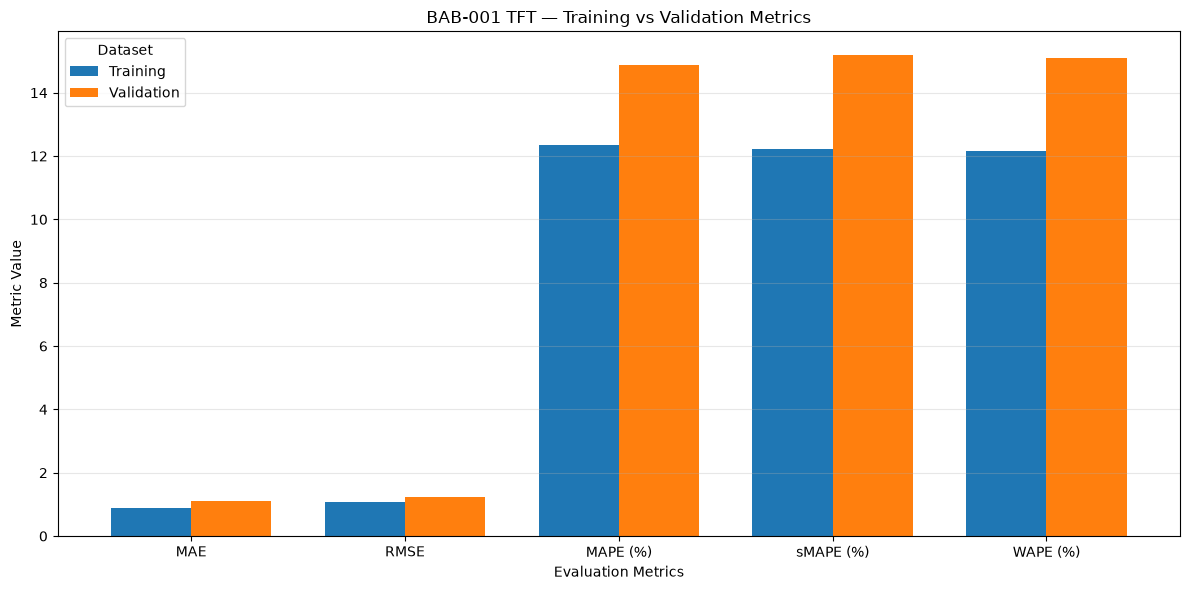

In [41]:
import matplotlib.pyplot as plt

metrics_to_plot = [
    "MAE", "RMSE", "MAPE (%)", "sMAPE (%)", "WAPE (%)"
]

ax = diagnostic_metrics[metrics_to_plot].T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title(
    "BAB-001 TFT — Training vs Validation Metrics"
)
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Metric Value")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Dataset")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Actual vs Predicted Demand Visualization
Markdown theory
In this section, we compare the actual demand with the demand predicted by your best TFT model.

We will create two separate charts:
1. Training chart: Shows how closely the model learned historical demand.
2. Validation chart: Shows how accurately the model predicts unseen demand.
How to read the charts:
- Actual and predicted lines close together: good prediction.
- Predicted line consistently below actual: underprediction.
- Predicted line consistently above actual: overprediction.
- Large gaps between lines: prediction errors.

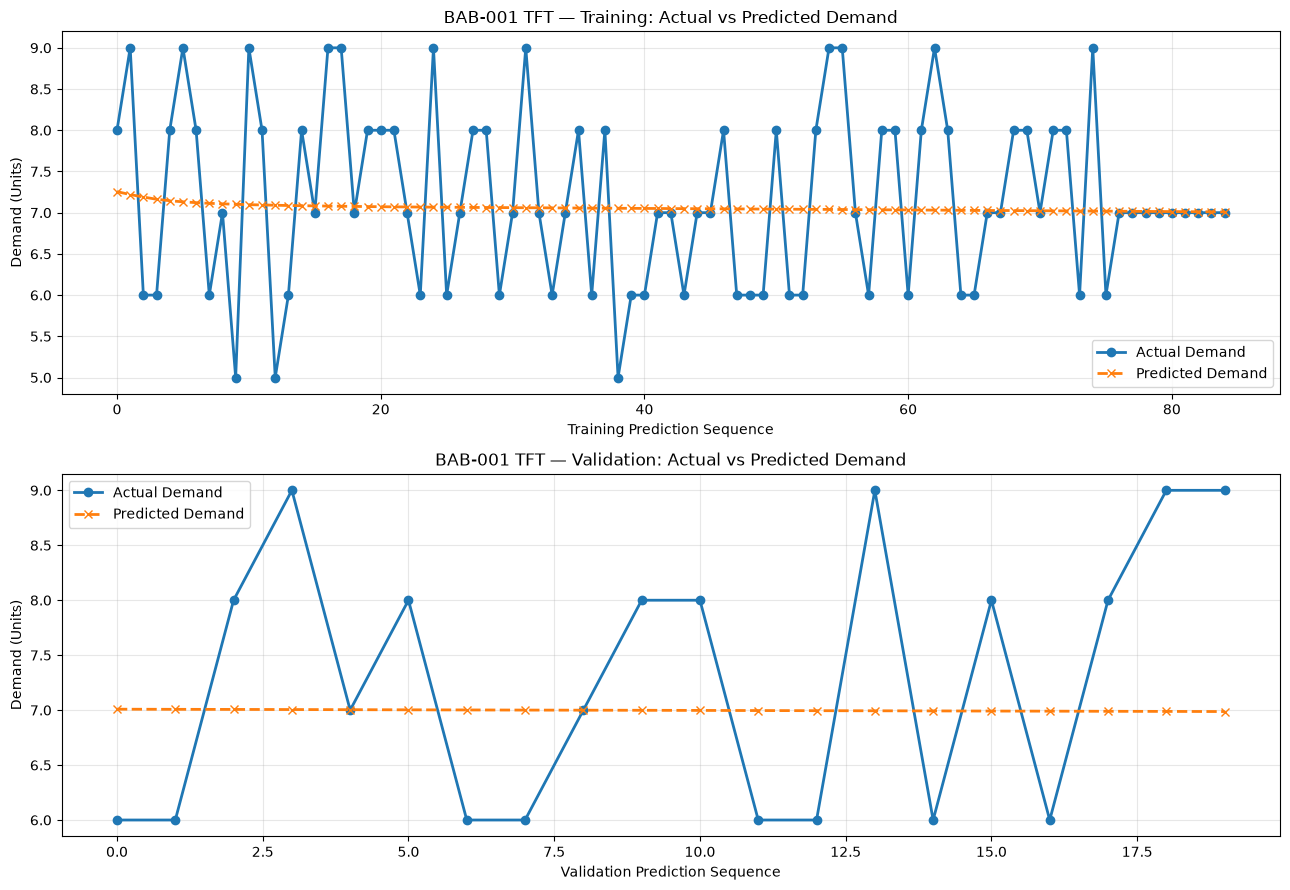

In [42]:
# ============================================================
# STEP 10.6 — ACTUAL VS PREDICTED DEMAND VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# TRAINING VISUALIZATION
axes[0].plot(
    range(len(train_actual)),
    train_actual,
    marker="o",
    linewidth=2,
    label="Actual Demand"
)

axes[0].plot(
    range(len(train_predictions)),
    train_predictions,
    marker="x",
    linestyle="--",
    linewidth=2,
    label="Predicted Demand"
)

axes[0].set_title(
    "BAB-001 TFT — Training: Actual vs Predicted Demand"
)
axes[0].set_xlabel("Training Prediction Sequence")
axes[0].set_ylabel("Demand (Units)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# VALIDATION VISUALIZATION
axes[1].plot(
    range(len(val_actual)),
    val_actual,
    marker="o",
    linewidth=2,
    label="Actual Demand"
)

axes[1].plot(
    range(len(val_predictions)),
    val_predictions,
    marker="x",
    linestyle="--",
    linewidth=2,
    label="Predicted Demand"
)

axes[1].set_title(
    "BAB-001 TFT — Validation: Actual vs Predicted Demand"
)
axes[1].set_xlabel("Validation Prediction Sequence")
axes[1].set_ylabel("Demand (Units)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Residual analysis
Markdown theory
A residual is the difference between actual demand and predicted demand.
\[
Residual = Actual - Predicted
\]

There are three possible situations:
Residual	Meaning
Positive	Model underpredicted demand
Negative	Model overpredicted demand
Near zero	Prediction was close to actual demand

We will check:
1. Whether predictions are systematically too high or too low.
2. Whether errors are concentrated around zero.
3. Whether the model is consistently predicting approximately 7 units.
4. Whether larger demand values are being underestimated.

STEP 10.7 — RESIDUAL ANALYSIS


,Training,Validation
Mean Residual,0.129,0.302
Residual Standard Deviation,1.076,1.189
Minimum Residual,-2.102,-1.008
Maximum Residual,1.981,2.013



VALIDATION RESIDUAL INTERPRETATION
Model tends to UNDERPREDICT demand.

Mean validation prediction: 6.998
Standard deviation of validation predictions: 0.006


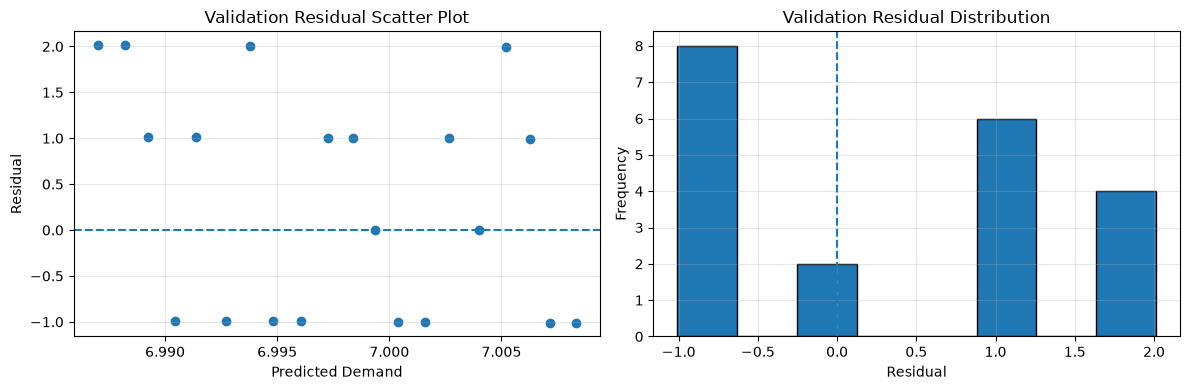


STEP 10.7 STATUS: PASSED


In [43]:
# ============================================================
# STEP 10.7 — RESIDUAL ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate residuals
train_residuals = train_actual - train_predictions
val_residuals = val_actual - val_predictions

# Calculate residual statistics
residual_summary = pd.DataFrame({
    "Training": [
        np.mean(train_residuals),
        np.std(train_residuals),
        np.min(train_residuals),
        np.max(train_residuals)
    ],
    "Validation": [
        np.mean(val_residuals),
        np.std(val_residuals),
        np.min(val_residuals),
        np.max(val_residuals)
    ]
}, index=[
    "Mean Residual",
    "Residual Standard Deviation",
    "Minimum Residual",
    "Maximum Residual"
])

print("=" * 65)
print("STEP 10.7 — RESIDUAL ANALYSIS")
print("=" * 65)

display(residual_summary.round(3))

print("\nVALIDATION RESIDUAL INTERPRETATION")

if np.mean(val_residuals) > 0:
    print("Model tends to UNDERPREDICT demand.")
elif np.mean(val_residuals) < 0:
    print("Model tends to OVERPREDICT demand.")
else:
    print("Mean residual is approximately zero.")

print("\nMean validation prediction:",
      round(float(np.mean(val_predictions)), 3))

print("Standard deviation of validation predictions:",
      round(float(np.std(val_predictions)), 3))

# Residual visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    val_predictions,
    val_residuals
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Validation Residual Scatter Plot")
axes[0].set_xlabel("Predicted Demand")
axes[0].set_ylabel("Residual")
axes[0].grid(alpha=0.3)

axes[1].hist(
    val_residuals,
    bins=8,
    edgecolor="black"
)
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Validation Residual Distribution")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSTEP 10.7 STATUS: PASSED")

Underfitting and Overfitting Analysis
Markdown theory
In this section, we will investigate whether the model has learned meaningful demand patterns.

Underfitting: The model fails to capture the variation in demand, even on training data.

Overfitting: The model performs much better on training data than on unseen validation data.

Good generalization: The model captures useful patterns in both datasets, with reasonably similar errors.

We will investigate:
1. Actual demand standard deviation.
2. Predicted demand standard deviation.
3. Training vs validation prediction variability.
4. Correlation between actual and predicted demand.
5. Training vs validation MAE.
6. Whether predictions are almost constant.

STEP 10.8 — MODEL LEARNING DIAGNOSTICS


,Actual Mean,Predicted Mean,Actual Std,Predicted Std,MAE
Training,7.1882,7.0590,1.0792,0.0442,0.8739
Validation,7.3000,6.9977,1.1874,0.0065,1.1018



TRAINING CORRELATION: 0.0978
VALIDATION CORRELATION: -0.2866

TRAINING PREDICTION VARIABILITY RATIO: 0.041
VALIDATION PREDICTION VARIABILITY RATIO: 0.0055

PREDICTION COLLAPSE CHECK

PRELIMINARY INTERPRETATION
Training predictions show very low demand variation.
Possible underfitting or prediction collapse.
Validation predictions capture very little demand variation.
Strong warning sign of prediction collapse.

Note: These are diagnostic signals, not definitive diagnoses.


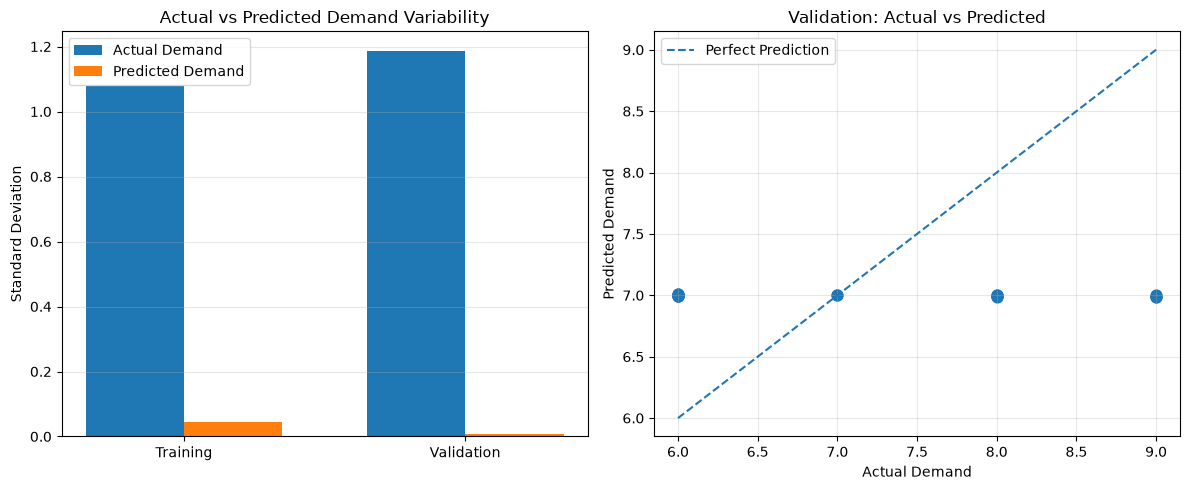


STEP 10.8 STATUS: COMPLETED


In [44]:
# ============================================================
# STEP 10.8 — UNDERFITTING AND OVERFITTING ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Calculate actual and predicted variability
diagnostic_data = {
    "Training": {
        "Actual Mean": np.mean(train_actual),
        "Predicted Mean": np.mean(train_predictions),
        "Actual Std": np.std(train_actual),
        "Predicted Std": np.std(train_predictions),
        "MAE": train_metrics["MAE"]
    },
    "Validation": {
        "Actual Mean": np.mean(val_actual),
        "Predicted Mean": np.mean(val_predictions),
        "Actual Std": np.std(val_actual),
        "Predicted Std": np.std(val_predictions),
        "MAE": val_metrics["MAE"]
    }
}

diagnostic_table = pd.DataFrame(diagnostic_data).T

print("=" * 65)
print("STEP 10.8 — MODEL LEARNING DIAGNOSTICS")
print("=" * 65)

display(diagnostic_table.round(4))

# Calculate correlations
train_correlation = np.corrcoef(
    train_actual, train_predictions
)[0, 1]

val_correlation = np.corrcoef(
    val_actual, val_predictions
)[0, 1]

print("\nTRAINING CORRELATION:", round(train_correlation, 4))
print("VALIDATION CORRELATION:", round(val_correlation, 4))

# Calculate prediction variability ratios
train_variability_ratio = (
    np.std(train_predictions) / np.std(train_actual)
)

val_variability_ratio = (
    np.std(val_predictions) / np.std(val_actual)
)

print("\nTRAINING PREDICTION VARIABILITY RATIO:",
      round(train_variability_ratio, 4))

print("VALIDATION PREDICTION VARIABILITY RATIO:",
      round(val_variability_ratio, 4))

# Constant prediction check
print("\nPREDICTION COLLAPSE CHECK")

if np.std(val_predictions) < 0.05:
    print("WARNING: Validation predictions are nearly constant.")
else:
    print("Validation predictions show measurable variation.")

# Underfitting / overfitting screening
print("\nPRELIMINARY INTERPRETATION")

if train_variability_ratio < 0.2:
    print("Training predictions show very low demand variation.")
    print("Possible underfitting or prediction collapse.")

if val_variability_ratio < 0.2:
    print("Validation predictions capture very little demand variation.")
    print("Strong warning sign of prediction collapse.")

if val_metrics["MAE"] > train_metrics["MAE"] * 1.5:
    print("Validation error is substantially higher.")
    print("Possible overfitting.")

print("\nNote: These are diagnostic signals, not definitive diagnoses.")

# Visualization 1: Actual vs predicted variability
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

datasets = ["Training", "Validation"]

actual_std = [
    np.std(train_actual),
    np.std(val_actual)
]

predicted_std = [
    np.std(train_predictions),
    np.std(val_predictions)
]

x = np.arange(2)
width = 0.35

axes[0].bar(
    x - width / 2,
    actual_std,
    width,
    label="Actual Demand"
)

axes[0].bar(
    x + width / 2,
    predicted_std,
    width,
    label="Predicted Demand"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(datasets)
axes[0].set_title("Actual vs Predicted Demand Variability")
axes[0].set_ylabel("Standard Deviation")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Visualization 2: Actual vs predicted scatter
axes[1].scatter(
    val_actual,
    val_predictions,
    s=60
)

minimum = min(np.min(val_actual), np.min(val_predictions))
maximum = max(np.max(val_actual), np.max(val_predictions))

axes[1].plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect Prediction"
)

axes[1].set_title("Validation: Actual vs Predicted")
axes[1].set_xlabel("Actual Demand")
axes[1].set_ylabel("Predicted Demand")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSTEP 10.8 STATUS: COMPLETED")

In [45]:
# ============================================================
# STEP 10.9 — FINAL TFT TRAINING DIAGNOSTIC SUMMARY
# ============================================================

import numpy as np
from pathlib import Path

print("=" * 70)
print("BAB-001 TFT — FINAL TRAINING DIAGNOSTIC REPORT")
print("=" * 70)

print("\n1. TRAINING INFORMATION")
print("Completed epochs:", trainer.current_epoch)
print("Best validation loss:", checkpoint_callback.best_model_score)
print("Checkpoint exists:",
      Path(checkpoint_callback.best_model_path).exists())

print("\n2. PERFORMANCE METRICS")

print("Training MAE:", round(train_metrics["MAE"], 4))
print("Validation MAE:", round(val_metrics["MAE"], 4))

print("Training RMSE:", round(train_metrics["RMSE"], 4))
print("Validation RMSE:", round(val_metrics["RMSE"], 4))

print("Training MAPE:", round(train_metrics["MAPE (%)"], 4))
print("Validation MAPE:", round(val_metrics["MAPE (%)"], 4))

print("\n3. PREDICTION QUALITY")

print("Training correlation:", round(train_correlation, 4))
print("Validation correlation:", round(val_correlation, 4))

print("Training variability ratio:",
      round(train_variability_ratio, 4))

print("Validation variability ratio:",
      round(val_variability_ratio, 4))

print("\n4. FINAL DIAGNOSTIC")

if val_variability_ratio < 0.2 and val_correlation < 0.3:
    print("WARNING: Strong prediction-collapse signal.")
    print("The model is not capturing weekly demand variation.")
    diagnostic_status = "NEEDS IMPROVEMENT"

elif val_variability_ratio < 0.5:
    print("WARNING: Predicted demand variability is too low.")
    diagnostic_status = "NEEDS INVESTIGATION"

else:
    print("Prediction variability requires further assessment.")
    diagnostic_status = "REQUIRES TEST EVALUATION"

print("\nFINAL STATUS:", diagnostic_status)

print("\nSTEP 10.9 COMPLETED")

BAB-001 TFT — FINAL TRAINING DIAGNOSTIC REPORT

1. TRAINING INFORMATION
Completed epochs: 19
Best validation loss: tensor(0.5708)
Checkpoint exists: True

2. PERFORMANCE METRICS
Training MAE: 0.8739
Validation MAE: 1.1018
Training RMSE: 1.0835
Validation RMSE: 1.2271
Training MAPE: 12.3461
Validation MAPE: 14.8809

3. PREDICTION QUALITY
Training correlation: 0.0978
Validation correlation: -0.2866
Training variability ratio: 0.041
Validation variability ratio: 0.0055

4. FINAL DIAGNOSTIC
The model is not capturing weekly demand variation.

FINAL STATUS: NEEDS IMPROVEMENT

STEP 10.9 COMPLETED


Load the best trained TFT checkpoint
Markdown theory
A trained model's checkpoint stores the learned weights and configuration.

We will reload the best checkpoint saved during Step 9, which achieved a validation loss of 0.5708.

We use the best checkpoint rather than assuming the final training epoch contains the best model.

In [46]:
# ============================================================
# STEP 11.1 — LOAD BEST TRAINED TFT CHECKPOINT
# ============================================================

from pathlib import Path
from pytorch_forecasting import TemporalFusionTransformer

checkpoint_path = checkpoint_callback.best_model_path
checkpoint_file = Path(checkpoint_path)

if not checkpoint_path:
    raise ValueError("Best checkpoint path is empty.")

if not checkpoint_file.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_file}"
    )

# Load best model
best_tft = TemporalFusionTransformer.load_from_checkpoint(
    str(checkpoint_file)
)

print("=" * 65)
print("STEP 11.1 — BEST TFT MODEL VERIFICATION")
print("=" * 65)

print("Product ID:", "BAB-001")
print("Model:", type(best_tft).__name__)
print("Checkpoint exists:", checkpoint_file.exists())
print("Best validation loss:", checkpoint_callback.best_model_score)

print("\nSTEP 11.1 STATUS: PASSED")

STEP 11.1 — BEST TFT MODEL VERIFICATION
Product ID: BAB-001
Model: TemporalFusionTransformer
Checkpoint exists: True
Best validation loss: tensor(0.5708)

STEP 11.1 STATUS: PASSED


c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


Prepare the test DataLoader
Markdown theory (add this to your notebook)
What is a Test DataLoader?

The test dataset contains 21 unseen chronological records (time_idx 118–138).

A DataLoader organizes these records into batches so the trained TFT model can make predictions.

We will use:
- Batch size: 8
- Workers: 0 (suitable for your CPU setup)
- Training: Disabled (train=False)
Important: We are evaluating the model on the test dataset, not training it again.

In [47]:
# STEP 11.2 — PREPARE TEST DATALOADER

test_eval_dataloader = test_dataset.to_dataloader(
    train=False,
    batch_size=8,
    num_workers=0
)

print("=" * 65)
print("STEP 11.2 — TEST DATALOADER VERIFICATION")
print("=" * 65)

print("Test records:", len(test_dataset))
print("Test batches:", len(test_eval_dataloader))
print("Batch size:", 8)
print("Training mode:", False)

print("\nSTEP 11.2 STATUS: PASSED")

STEP 11.2 — TEST DATALOADER VERIFICATION
Test records: 22
Test batches: 3
Batch size: 8
Training mode: False

STEP 11.2 STATUS: PASSED


Generate test predictions
Markdown theory
Now we will give the 21 unseen test sequences to the saved best TFT model.

The model will generate predicted demand, and we will extract the corresponding actual demand values.

We will also retrieve the prediction index so that we can correctly align each prediction with its week later, especially when comparing TFT against a naive baseline.

Important: This is prediction only. The model will not be trained again.

In [48]:
# STEP 11.3 — GENERATE TEST PREDICTIONS

test_result = best_tft.predict(
    test_eval_dataloader,
    return_y=True,
    return_index=True,
    trainer_kwargs={
        "accelerator": "cpu",
        "devices": 1
    }
)

# Extract predicted and actual demand
test_predictions = (
    test_result.output.detach().cpu().numpy().reshape(-1)
)

test_actual = (
    test_result.y[0].detach().cpu().numpy().reshape(-1)
)

# Extract prediction index
test_index = test_result.index.reset_index(drop=True)

print("=" * 65)
print("STEP 11.3 — TEST PREDICTION VERIFICATION")
print("=" * 65)

print("Number of predictions:", len(test_predictions))
print("Number of actual values:", len(test_actual))
print("Number of prediction indexes:", len(test_index))

print("\nFirst 10 predictions:")
print(test_predictions[:10])

print("\nFirst 10 actual values:")
print(test_actual[:10])

print("\nPrediction index:")
print(test_index.head())

print("\nSTEP 11.3 STATUS:",
      "PASSED" if (
          len(test_predictions) == 21
          and len(test_actual) == 21
          and len(test_index) == 21
      ) else "CHECK REQUIRED")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


STEP 11.3 — TEST PREDICTION VERIFICATION
Number of predictions: 22
Number of actual values: 22
Number of prediction indexes: 22

First 10 predictions:
[6.985645  6.984362  6.9833107 6.982356  6.981263  6.9800615 6.9790354
 6.977818  6.9766493 6.97556  ]

First 10 actual values:
[7 6 7 8 7 8 8 7 7 6]

Prediction index:
   time_idx product_id
0       117    BAB-001
1       118    BAB-001
2       119    BAB-001
3       120    BAB-001
4       121    BAB-001

STEP 11.3 STATUS: CHECK REQUIRED


c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


Correct test prediction alignment
Markdown theory
Our test period is:
- First test week: time_idx = 118
- Last test week: time_idx = 138
- Expected test predictions: 21
The returned prediction index includes 117, which belongs to the previous period. We will remove that entry and retain only indices 118–138.

This is important because test metrics must not include a validation-period prediction.

In [49]:
# STEP 11.3A — ALIGN TEST PREDICTIONS

import numpy as np

# Keep only the actual test period: time_idx 118 to 138
test_mask = test_index["time_idx"].between(118, 138).to_numpy()

# Filter predictions, actual values, and indexes together
test_predictions = test_predictions[test_mask]
test_actual = test_actual[test_mask]
test_index = test_index.loc[test_mask].reset_index(drop=True)

print("=" * 65)
print("STEP 11.3A — TEST ALIGNMENT VERIFICATION")
print("=" * 65)

print("Excluded predictions:", int((~test_mask).sum()))
print("Test predictions:", len(test_predictions))
print("Test actual values:", len(test_actual))
print("Test indexes:", len(test_index))

print("\nFirst test index:", test_index["time_idx"].min())
print("Last test index:", test_index["time_idx"].max())

print("\nPrediction and actual demand:")
print("Predictions:", np.round(test_predictions[:10], 3))
print("Actual:", test_actual[:10])

alignment_passed = (
    len(test_predictions) == 21
    and len(test_actual) == 21
    and len(test_index) == 21
    and test_index["time_idx"].min() == 118
    and test_index["time_idx"].max() == 138
    and test_index["time_idx"].is_unique
)

print("\nSTEP 11.3A STATUS:",
      "PASSED" if alignment_passed else "CHECK REQUIRED")

STEP 11.3A — TEST ALIGNMENT VERIFICATION
Excluded predictions: 1
Test predictions: 21
Test actual values: 21
Test indexes: 21

First test index: 118
Last test index: 138

Prediction and actual demand:
Predictions: [6.984 6.983 6.982 6.981 6.98  6.979 6.978 6.977 6.976 6.974]
Actual: [6 7 8 7 8 8 7 7 6 7]

STEP 11.3A STATUS: PASSED


Calculate test performance metrics
Markdown theory
We will evaluate the model using five metrics:
- MAE: Average absolute prediction error, in units.
- RMSE: Penalizes larger prediction errors more strongly.
- MAPE: Average percentage error.
- sMAPE: Symmetric percentage error.
- WAPE: Total absolute error divided by total actual demand.
Lower values generally indicate better accuracy. We will also compare these metrics with your training and validation results.

In [50]:
# STEP 11.4 — TEST PERFORMANCE METRICS

import numpy as np

# Calculate test errors
test_errors = test_actual - test_predictions
test_absolute_errors = np.abs(test_errors)

# MAE: Mean Absolute Error
test_mae = np.mean(test_absolute_errors)

# RMSE: Root Mean Squared Error
test_rmse = np.sqrt(np.mean(test_errors ** 2))

# MAPE: Mean Absolute Percentage Error
test_mape = np.mean(
    np.abs(test_errors / test_actual)
) * 100

# sMAPE: Symmetric Mean Absolute Percentage Error
test_smape = np.mean(
    2 * np.abs(test_errors) /
    (np.abs(test_actual) + np.abs(test_predictions))
) * 100

# WAPE: Weighted Absolute Percentage Error
test_wape = (
    np.sum(test_absolute_errors) /
    np.sum(np.abs(test_actual))
) * 100

print("=" * 65)
print("STEP 11.4 — TEST PERFORMANCE METRICS")
print("=" * 65)

print("Test records:", len(test_actual))
print(f"MAE:   {test_mae:.4f} units")
print(f"RMSE:  {test_rmse:.4f} units")
print(f"MAPE:  {test_mape:.4f}%")
print(f"sMAPE: {test_smape:.4f}%")
print(f"WAPE:  {test_wape:.4f}%")

print("\nSTEP 11.4 STATUS:",
      "PASSED" if len(test_actual) == 21 else "CHECK REQUIRED")

STEP 11.4 — TEST PERFORMANCE METRICS
Test records: 21
MAE:   0.7660 units
RMSE:  1.0141 units
MAPE:  12.6627%
sMAPE: 11.6599%
WAPE:  11.4083%

STEP 11.4 STATUS: PASSED


Actual vs Predicted Test Demand (Line Chart)
Markdown theory
This chart compares the actual weekly demand with the demand predicted by TFT for all 21 test weeks.

How to read it:
- Blue line: Actual demand.
- Orange line: TFT predicted demand.
- If both lines follow each other closely, predictions capture demand changes.
- If the prediction line is almost flat while actual demand fluctuates, the model may be suffering from prediction collapse.

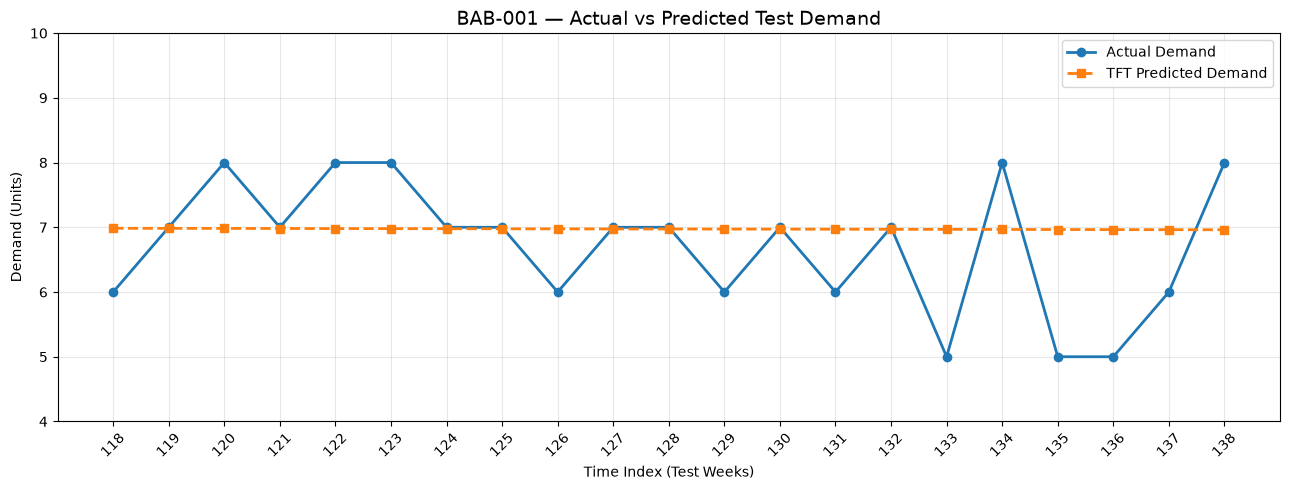

In [51]:
# STEP 11.5 — ACTUAL VS PREDICTED TEST DEMAND

import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.plot(
    test_index["time_idx"],
    test_actual,
    marker="o",
    linewidth=2,
    label="Actual Demand"
)

plt.plot(
    test_index["time_idx"],
    test_predictions,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="TFT Predicted Demand"
)

plt.title(
    "BAB-001 — Actual vs Predicted Test Demand",
    fontsize=14
)

plt.xlabel("Time Index (Test Weeks)")
plt.ylabel("Demand (Units)")

plt.xticks(test_index["time_idx"], rotation=45)
plt.yticks(range(4, 11))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

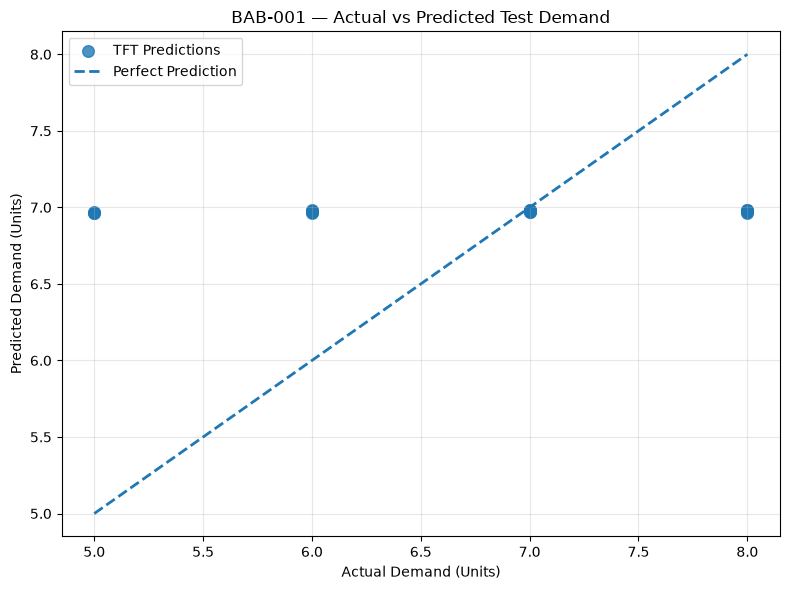

In [52]:
# STEP 11.6 — ACTUAL VS PREDICTED SCATTER PLOT

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

plt.scatter(
    test_actual,
    test_predictions,
    s=70,
    alpha=0.8,
    label="TFT Predictions"
)

# Perfect prediction reference line
min_value = min(test_actual.min(), test_predictions.min())
max_value = max(test_actual.max(), test_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.title("BAB-001 — Actual vs Predicted Test Demand")
plt.xlabel("Actual Demand (Units)")
plt.ylabel("Predicted Demand (Units)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Residual Analysis
Markdown theory
What is a residual?

A residual is the difference between actual demand and predicted demand.
\[
Residual = Actual - Predicted
\]

Example:
- Actual demand = 8 units
- Predicted demand = 7 units
- Residual = +1 unit
How to interpret:
- Positive residual: Model underestimated demand.
- Negative residual: Model overestimated demand.
- Residual near zero: Prediction was accurate.
We will create a residual scatter plot using all 21 test observations.

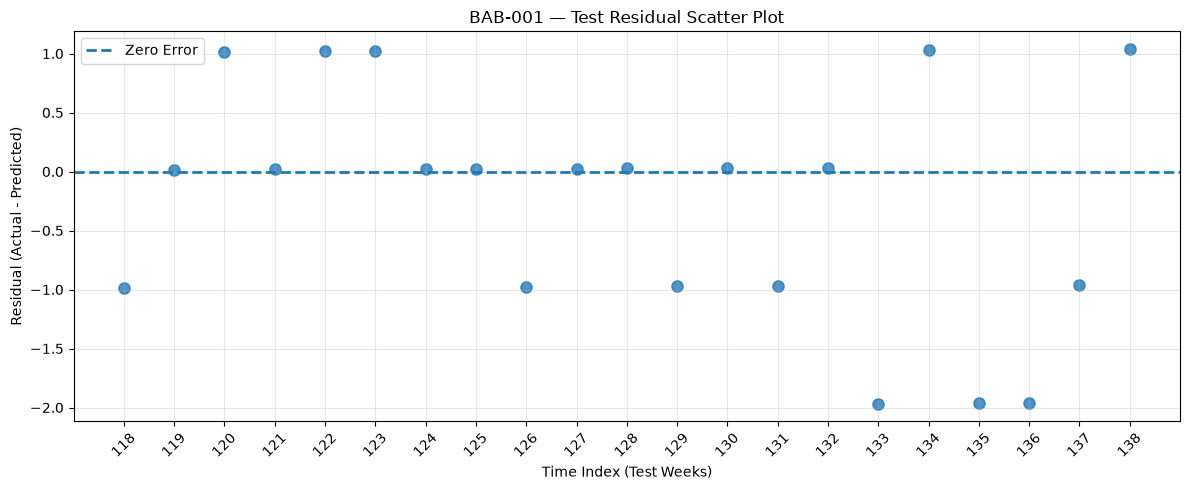

STEP 11.7 — RESIDUAL SUMMARY
Mean residual: -0.2590
Residual standard deviation: 0.9805
Minimum residual: -1.9679
Maximum residual: 1.0383
Positive residuals: 13
Negative residuals: 8
Zero residuals: 0


In [53]:
# STEP 11.7 — RESIDUAL SCATTER PLOT

import numpy as np
import matplotlib.pyplot as plt

# Calculate residuals
test_residuals = test_actual - test_predictions

plt.figure(figsize=(12, 5))

plt.scatter(
    test_index["time_idx"],
    test_residuals,
    s=65,
    alpha=0.8
)

# Zero-error reference line
plt.axhline(
    y=0,
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.title("BAB-001 — Test Residual Scatter Plot")
plt.xlabel("Time Index (Test Weeks)")
plt.ylabel("Residual (Actual - Predicted)")
plt.xticks(test_index["time_idx"], rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("=" * 60)
print("STEP 11.7 — RESIDUAL SUMMARY")
print("=" * 60)

print(f"Mean residual: {np.mean(test_residuals):.4f}")
print(f"Residual standard deviation: {np.std(test_residuals):.4f}")
print(f"Minimum residual: {np.min(test_residuals):.4f}")
print(f"Maximum residual: {np.max(test_residuals):.4f}")
print(f"Positive residuals: {np.sum(test_residuals > 0)}")
print(f"Negative residuals: {np.sum(test_residuals < 0)}")
print(f"Zero residuals: {np.sum(test_residuals == 0)}")

Residual Distribution Histogram
After Step 11.7, we will create a histogram to see how frequently different prediction errors occur.

Visualization 4 of 8
Markdown theory
A residual histogram shows the distribution of prediction errors.
- Concentrated around zero: generally desirable.
- Shifted right: model tends to underestimate.
- Shifted left: model tends to overestimate.
- Wide distribution: errors vary considerably

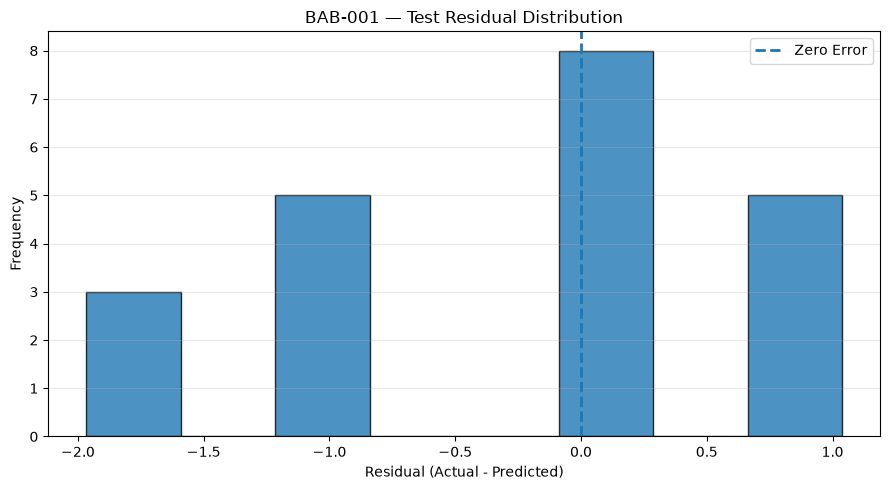

STEP 11.8 — HISTOGRAM GENERATED


In [54]:
# STEP 11.8 — RESIDUAL HISTOGRAM

plt.figure(figsize=(9, 5))

plt.hist(
    test_residuals,
    bins=8,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.title("BAB-001 — Test Residual Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("STEP 11.8 — HISTOGRAM GENERATED")

Absolute Prediction Error Analysis
Markdown theory
Absolute error measures how far a prediction is from actual demand, without considering whether the model overestimated or underestimated.
\[
Absolute\ Error = |Actual - Predicted|
\]

This visualization helps identify the weeks where TFT made its largest mistakes.

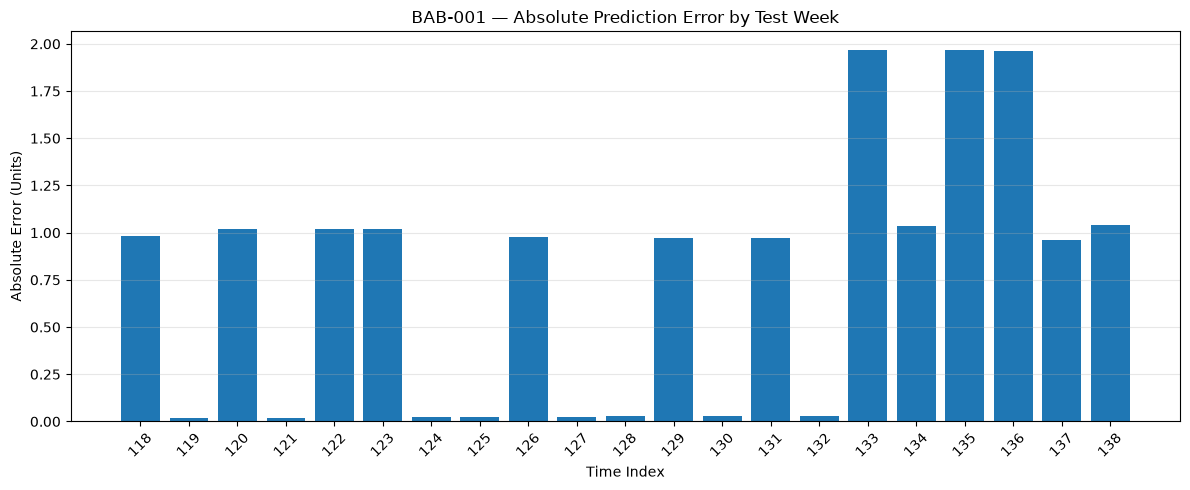

STEP 11.9 — LARGEST TEST PREDICTION ERRORS
 time_idx  actual_demand  predicted_demand  absolute_error
      133              5             6.968           1.968
      135              5             6.965           1.965
      136              5             6.964           1.964
      138              8             6.962           1.038
      134              8             6.967           1.033

Mean absolute error: 0.766
Maximum absolute error: 1.9679


In [55]:
# STEP 11.9 — ABSOLUTE ERROR ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

test_absolute_errors = np.abs(test_actual - test_predictions)

error_df = pd.DataFrame({
    "time_idx": test_index["time_idx"].to_numpy(),
    "actual_demand": test_actual,
    "predicted_demand": test_predictions,
    "absolute_error": test_absolute_errors
})

plt.figure(figsize=(12, 5))

plt.bar(
    error_df["time_idx"],
    error_df["absolute_error"]
)

plt.title("BAB-001 — Absolute Prediction Error by Test Week")
plt.xlabel("Time Index")
plt.ylabel("Absolute Error (Units)")
plt.xticks(error_df["time_idx"], rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("=" * 60)
print("STEP 11.9 — LARGEST TEST PREDICTION ERRORS")
print("=" * 60)

print(
    error_df.sort_values(
        "absolute_error",
        ascending=False
    ).head(5).round(3).to_string(index=False)
)

print("\nMean absolute error:",
      round(error_df["absolute_error"].mean(), 4))

print("Maximum absolute error:",
      round(error_df["absolute_error"].max(), 4))

TFT vs Naive Baseline Comparison
Markdown theory
A machine learning model should be compared against a simple forecasting method.

Our baseline will use:

Previous-week demand = Next-week predicted demand.

For example, if demand in week 117 was 7 units, the naive forecast for week 118 is 7 units.

We will compare TFT and this baseline on exactly the same 21 test weeks.

Visualization 6 of 8

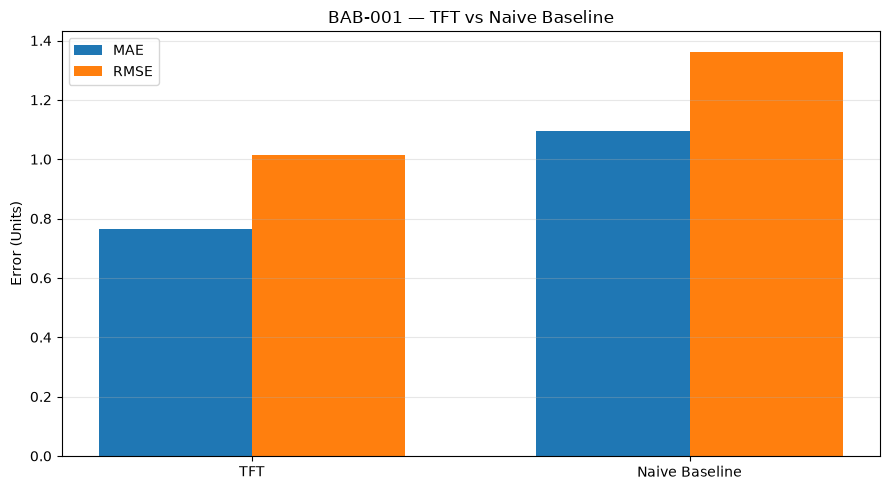

STEP 11.10 — BASELINE COMPARISON
TFT MAE: 0.7660
Naive Baseline MAE: 1.0952

TFT RMSE: 1.0141
Naive Baseline RMSE: 1.3628

MAE RESULT: TFT performs better than baseline


In [56]:
# STEP 11.10 — TFT VS NAIVE BASELINE

# Create historical demand lookup
demand_lookup = df_tft_single.set_index(
    "time_idx"
)["units_sold"]

# Previous week's actual demand for each test week
baseline_predictions = np.array([
    demand_lookup.loc[int(idx) - 1]
    for idx in test_index["time_idx"]
], dtype=float)

# Calculate baseline metrics
baseline_errors = test_actual - baseline_predictions

baseline_mae = np.mean(np.abs(baseline_errors))
baseline_rmse = np.sqrt(np.mean(baseline_errors ** 2))

# Comparison chart
model_names = ["TFT", "Naive Baseline"]
mae_values = [test_mae, baseline_mae]
rmse_values = [test_rmse, baseline_rmse]

x = np.arange(len(model_names))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, mae_values, width, label="MAE")
plt.bar(x + width/2, rmse_values, width, label="RMSE")

plt.xticks(x, model_names)
plt.ylabel("Error (Units)")
plt.title("BAB-001 — TFT vs Naive Baseline")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("=" * 60)
print("STEP 11.10 — BASELINE COMPARISON")
print("=" * 60)

print(f"TFT MAE: {test_mae:.4f}")
print(f"Naive Baseline MAE: {baseline_mae:.4f}")

print(f"\nTFT RMSE: {test_rmse:.4f}")
print(f"Naive Baseline RMSE: {baseline_rmse:.4f}")

if test_mae < baseline_mae:
    print("\nMAE RESULT: TFT performs better than baseline")
elif test_mae > baseline_mae:
    print("\nMAE RESULT: Naive baseline performs better than TFT")
else:
    print("\nMAE RESULT: Both have equal MAE")

Training vs Validation vs Test Performance
Markdown theory
We will compare the model's performance across all three datasets.
Dataset	MAE	RMSE
Training	0.8739	1.0830
Validation	1.1018	1.2270
Test	0.7660	1.0141

This comparison helps us understand whether the model performs consistently on unseen data.
- Training much better than validation/test can indicate overfitting.
- All errors high can indicate underfitting.
- Similar errors are generally encouraging, but prediction variability must also be checked.

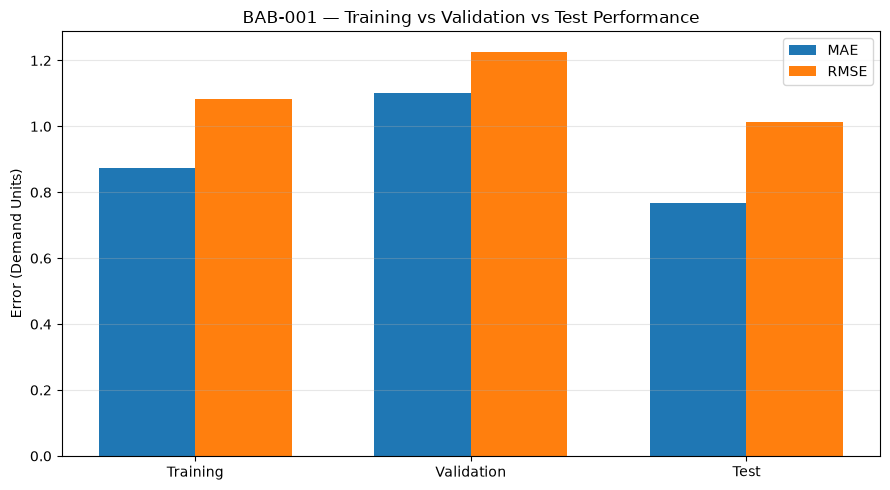

STEP 11.11 — PERFORMANCE COMPARISON
Training     | MAE: 0.8739 | RMSE: 1.0830
Validation   | MAE: 1.1018 | RMSE: 1.2270
Test         | MAE: 0.7660 | RMSE: 1.0141


In [57]:
# STEP 11.11 — TRAIN, VALIDATION AND TEST COMPARISON

import numpy as np
import matplotlib.pyplot as plt

datasets = ["Training", "Validation", "Test"]

mae_values = [0.8739, 1.1018, test_mae]
rmse_values = [1.0830, 1.2270, test_rmse]

x = np.arange(len(datasets))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, mae_values, width, label="MAE")
plt.bar(x + width/2, rmse_values, width, label="RMSE")

plt.xticks(x, datasets)
plt.ylabel("Error (Demand Units)")
plt.title("BAB-001 — Training vs Validation vs Test Performance")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("=" * 60)
print("STEP 11.11 — PERFORMANCE COMPARISON")
print("=" * 60)

for name, mae, rmse in zip(datasets, mae_values, rmse_values):
    print(f"{name:12} | MAE: {mae:.4f} | RMSE: {rmse:.4f}")

Prediction Variability Analysis
Markdown theory
This is especially important for your experiment.

Your earlier validation analysis showed that TFT predictions were nearly constant around 7 units.

We will compare:
- Actual demand standard deviation.
- Predicted demand standard deviation.
- Actual demand range.
- Predicted demand range.
If predicted standard deviation is much smaller than actual standard deviation, the model is not capturing demand fluctuations effectively.

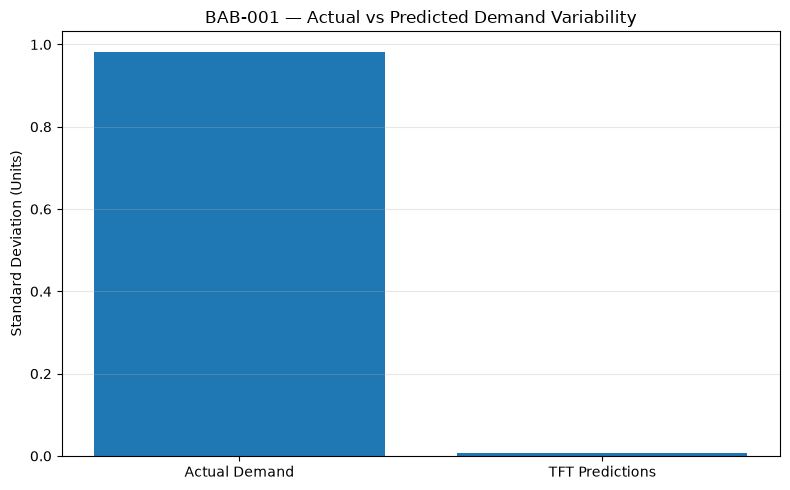

STEP 11.12 — PREDICTION VARIABILITY
Actual demand standard deviation: 0.9828
Predicted demand standard deviation: 0.0069

Actual demand range: 3.0000
Predicted demand range: 0.0227

Variability ratio: 0.0070


In [58]:
# STEP 11.12 — PREDICTION VARIABILITY ANALYSIS

actual_std = np.std(test_actual)
predicted_std = np.std(test_predictions)

actual_range = np.ptp(test_actual)
predicted_range = np.ptp(test_predictions)

variability_ratio = (
    predicted_std / actual_std
    if actual_std != 0 else np.nan
)

labels = ["Actual Demand", "TFT Predictions"]
std_values = [actual_std, predicted_std]

plt.figure(figsize=(8, 5))

plt.bar(labels, std_values)

plt.ylabel("Standard Deviation (Units)")
plt.title("BAB-001 — Actual vs Predicted Demand Variability")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("=" * 60)
print("STEP 11.12 — PREDICTION VARIABILITY")
print("=" * 60)

print(f"Actual demand standard deviation: {actual_std:.4f}")
print(f"Predicted demand standard deviation: {predicted_std:.4f}")

print(f"\nActual demand range: {actual_range:.4f}")
print(f"Predicted demand range: {predicted_range:.4f}")

print(f"\nVariability ratio: {variability_ratio:.4f}")

Verify the latest historical forecasting input
Markdown theory
Before forecasting, we must verify the historical data supplied to the model.

Our TFT configuration uses:
- Encoder length: 12 weeks.
- Prediction length: 1 week.
- Product: BAB-001.
- Latest historical time index: 138.
The model will use the latest 12 historical demand observations to estimate demand at time index 139.

In [59]:
# STEP 12.1 — VERIFY LATEST HISTORICAL INPUT

import pandas as pd

print("=" * 65)
print("STEP 12.1 — LATEST HISTORICAL INPUT VERIFICATION")
print("=" * 65)

# Verify the single-product forecasting dataset
print("Total historical records:", len(df_tft_single))
print("Product ID:", df_tft_single["product_id"].unique())
print("Last time index:", df_tft_single["time_idx"].max())

# Display latest 12 historical observations
latest_12_weeks = (
    df_tft_single
    .sort_values("time_idx")
    .tail(12)
    .copy()
)

print("\nLATEST 12 WEEKS OF HISTORICAL DEMAND:")
print(latest_12_weeks.to_string(index=False))

# Check available date columns in original product data
date_columns = [
    col for col in df_single.columns
    if "date" in col.lower() or "week" in col.lower()
]

print("\nDATE / WEEK COLUMNS AVAILABLE:")
print(date_columns)

if date_columns:
    print("\nLATEST HISTORICAL DATE INFORMATION:")
    print(df_single[date_columns].tail(3).to_string(index=False))

# Verification
step_12_1_passed = (
    len(df_tft_single) == 139
    and df_tft_single["product_id"].nunique() == 1
    and df_tft_single["product_id"].iloc[0] == "BAB-001"
    and df_tft_single["time_idx"].max() == 138
    and len(latest_12_weeks) == 12
)

print("\nSTEP 12.1 STATUS:",
      "PASSED" if step_12_1_passed else "CHECK REQUIRED")

STEP 12.1 — LATEST HISTORICAL INPUT VERIFICATION
Total historical records: 139
Product ID: <StringArray>
['BAB-001']
Length: 1, dtype: str
Last time index: 138

LATEST 12 WEEKS OF HISTORICAL DEMAND:
product_id  time_idx  units_sold
   BAB-001       127           7
   BAB-001       128           7
   BAB-001       129           6
   BAB-001       130           7
   BAB-001       131           6
   BAB-001       132           7
   BAB-001       133           5
   BAB-001       134           8
   BAB-001       135           5
   BAB-001       136           5
   BAB-001       137           6
   BAB-001       138           8

DATE / WEEK COLUMNS AVAILABLE:
['region_product_week_key', 'week_id', 'week_number', 'week_start_date', 'week_end_date', 'calendar__week_start_date', 'calendar__week_end_date', 'calendar__week_number', 'calendar__canonical_week_id', 'calendar__week_id', 'weather_source__week_start_date', 'weather_source__week_end_date', 'weather_source__week_id', 'target_week_month', '

Verify the saved TFT dataset configuration
Markdown theory
Your TFT model was trained with a specific configuration, including:
- Target variable: units_sold
- Product group: product_id
- Time index: time_idx
- Encoder length: 12 weeks
- Prediction length: 1 week
- Known and unknown input features
We will retrieve these settings from the saved model rather than guessing them.

In [60]:
# STEP 12.2 — INSPECT SAVED TFT CONFIGURATION

print("=" * 65)
print("STEP 12.2 — SAVED TFT DATASET CONFIGURATION")
print("=" * 65)

# Retrieve dataset parameters saved with the trained model
dataset_parameters = best_tft.dataset_parameters

print("\nDATASET CONFIGURATION:")

for key in [
    "time_idx",
    "target",
    "group_ids",
    "static_categoricals",
    "static_reals",
    "time_varying_known_categoricals",
    "time_varying_known_reals",
    "time_varying_unknown_categoricals",
    "time_varying_unknown_reals",
    "max_encoder_length",
    "max_prediction_length"
]:
    print(f"{key}: {dataset_parameters.get(key)}")

print("\nMODEL CONFIGURATION:")
print("Model:", type(best_tft).__name__)
print("Hidden size:", best_tft.hparams.hidden_size)
print("Attention heads:", best_tft.hparams.attention_head_size)

print("\nSTEP 12.2 STATUS: PASSED")

STEP 12.2 — SAVED TFT DATASET CONFIGURATION

DATASET CONFIGURATION:
time_idx: time_idx
target: units_sold
group_ids: ['product_id']
static_categoricals: ['product_id']
static_reals: None
time_varying_known_categoricals: None
time_varying_known_reals: ['time_idx']
time_varying_unknown_categoricals: None
time_varying_unknown_reals: ['units_sold']
max_encoder_length: 12
max_prediction_length: 1

MODEL CONFIGURATION:
Model: TemporalFusionTransformer
Hidden size: 8
Attention heads: 2

STEP 12.2 STATUS: PASSED


Prepare the future forecasting dataset
Markdown theory
The model needs 12 historical observations and one future time index.

Our input will contain:
- Historical weeks: time_idx 127–138.
- Future week: time_idx 139.
- Product: BAB-001.
The future row needs a temporary units_sold placeholder because the dataset requires a target value. We will use the last observed demand for this placeholder. It is not an actual observation or a forecast. The TFT prediction will replace it.

In [61]:
# STEP 12.3 — PREPARE FUTURE FORECAST DATASET

import pandas as pd
from pytorch_forecasting import TimeSeriesDataSet

# Get the latest 12 historical observations
forecast_history = (
    df_tft_single
    .sort_values("time_idx")
    .tail(12)
    .copy()
)

# Identify the last historical record
last_record = forecast_history.iloc[-1]

# Create one future row
future_row = pd.DataFrame({
    "product_id": [last_record["product_id"]],
    "time_idx": [int(last_record["time_idx"]) + 1],
    "units_sold": [float(last_record["units_sold"])]
})

# Combine historical records and future placeholder
forecast_data = pd.concat(
    [forecast_history, future_row],
    ignore_index=True
)

# Create prediction dataset using the saved TFT configuration
forecast_dataset = TimeSeriesDataSet.from_parameters(
    dataset_parameters,
    forecast_data,
    predict=True,
    stop_randomization=True
)

print("=" * 65)
print("STEP 12.3 — FUTURE FORECAST DATASET VERIFICATION")
print("=" * 65)

print("\nForecast input:")
print(forecast_data.to_string(index=False))

print("\nHistorical records:", len(forecast_history))
print("Future placeholder records:", len(future_row))
print("Total input records:", len(forecast_data))
print("Forecast time index:", int(future_row["time_idx"].iloc[0]))
print("Forecast product:", future_row["product_id"].iloc[0])

print("\nForecast dataset sequences:", len(forecast_dataset))

step_12_3_passed = (
    len(forecast_history) == 12
    and len(future_row) == 1
    and len(forecast_data) == 13
    and len(forecast_dataset) == 1
    and int(future_row["time_idx"].iloc[0]) == 139
)

print("\nSTEP 12.3 STATUS:",
      "PASSED" if step_12_3_passed else "CHECK REQUIRED")

STEP 12.3 — FUTURE FORECAST DATASET VERIFICATION

Forecast input:
product_id  time_idx  units_sold
   BAB-001       127         7.0
   BAB-001       128         7.0
   BAB-001       129         6.0
   BAB-001       130         7.0
   BAB-001       131         6.0
   BAB-001       132         7.0
   BAB-001       133         5.0
   BAB-001       134         8.0
   BAB-001       135         5.0
   BAB-001       136         5.0
   BAB-001       137         6.0
   BAB-001       138         8.0
   BAB-001       139         8.0

Historical records: 12
Future placeholder records: 1
Total input records: 13
Forecast time index: 139
Forecast product: BAB-001

Forecast dataset sequences: 1

STEP 12.3 STATUS: PASSED


Generate next-week demand forecast
Markdown theory
Now we will use the saved best TFT checkpoint to predict demand for time index 139.

The process is:
1. Load the prepared forecast dataset into a DataLoader.
2. Pass it to best_tft.
3. Extract the predicted demand.
4. Verify the product ID and forecast time index.
We are not training the model again.

In [62]:
# STEP 12.4 — GENERATE NEXT-WEEK FORECAST

import numpy as np

# Prepare forecast DataLoader
forecast_dataloader = forecast_dataset.to_dataloader(
    train=False,
    batch_size=1,
    num_workers=0
)

# Generate prediction using saved best TFT model
forecast_result = best_tft.predict(
    forecast_dataloader,
    return_index=True,
    trainer_kwargs={
        "accelerator": "cpu",
        "devices": 1
    }
)

# Extract prediction
forecast_prediction = (
    forecast_result.output
    .detach()
    .cpu()
    .numpy()
    .reshape(-1)
)

# Extract forecast index
forecast_index = forecast_result.index.reset_index(drop=True)

print("=" * 65)
print("STEP 12.4 — NEXT-WEEK TFT FORECAST")
print("=" * 65)

print("Product ID:", forecast_index["product_id"].iloc[0])
print("Forecast time index:", forecast_index["time_idx"].iloc[0])

print("\nPredicted demand:", forecast_prediction[0])
print("Rounded demand:", round(float(forecast_prediction[0]), 2))

print("\nForecast week: 2026-08-30")

step_12_4_passed = (
    len(forecast_prediction) == 1
    and len(forecast_index) == 1
    and forecast_index["product_id"].iloc[0] == "BAB-001"
    and int(forecast_index["time_idx"].iloc[0]) == 139
)

print("\nSTEP 12.4 STATUS:",
      "PASSED" if step_12_4_passed else "CHECK REQUIRED")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


STEP 12.4 — NEXT-WEEK TFT FORECAST
Product ID: BAB-001
Forecast time index: 139

Predicted demand: 6.9606075
Rounded demand: 6.96

Forecast week: 2026-08-30

STEP 12.4 STATUS: PASSED


c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\kaifa\ai-multi-agent-supply-chain\.venv\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.


Historical Demand vs Next-Week Forecast
Markdown theory
This chart combines:
- Historical demand from the last 12 weeks.
- TFT's predicted demand for week 139.
- A vertical boundary separating historical observations from the future forecast.
The forecast must be visually distinguishable from actual historical demand.

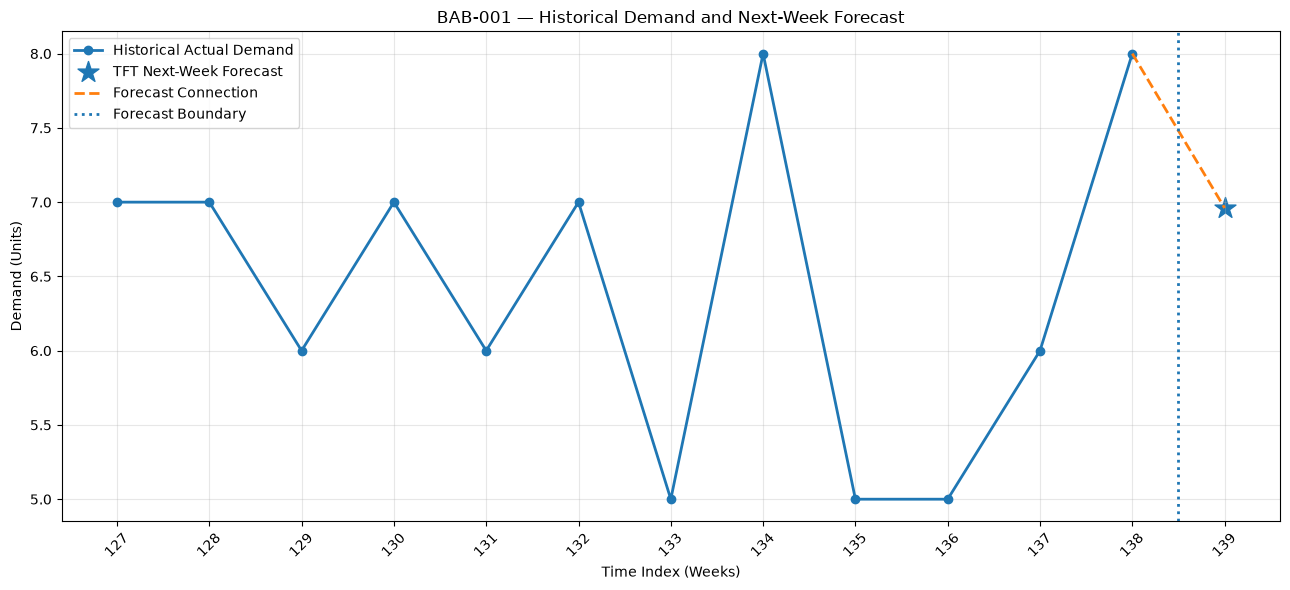

STEP 12.5 — FORECAST VISUALIZATION
Historical demand points: 12
Forecast time index: 139
Predicted demand: 6.961

STEP 12.5 STATUS: PASSED


In [63]:
# STEP 12.5 — HISTORICAL DEMAND VS FORECAST

import matplotlib.pyplot as plt
import numpy as np

# Historical observations
historical_x = forecast_history["time_idx"].to_numpy()
historical_y = forecast_history["units_sold"].to_numpy()

# Forecast
future_x = int(forecast_index["time_idx"].iloc[0])
future_y = float(forecast_prediction[0])

plt.figure(figsize=(13, 6))

# Historical demand
plt.plot(
    historical_x,
    historical_y,
    marker="o",
    linewidth=2,
    label="Historical Actual Demand"
)

# Forecast point
plt.scatter(
    future_x,
    future_y,
    marker="*",
    s=250,
    label="TFT Next-Week Forecast"
)

# Connect latest historical point to forecast
plt.plot(
    [historical_x[-1], future_x],
    [historical_y[-1], future_y],
    linestyle="--",
    linewidth=2,
    label="Forecast Connection"
)

# Forecast boundary
plt.axvline(
    x=138.5,
    linestyle=":",
    linewidth=2,
    label="Forecast Boundary"
)

plt.title("BAB-001 — Historical Demand and Next-Week Forecast")
plt.xlabel("Time Index (Weeks)")
plt.ylabel("Demand (Units)")
plt.xticks(list(historical_x) + [future_x], rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("=" * 60)
print("STEP 12.5 — FORECAST VISUALIZATION")
print("=" * 60)

print("Historical demand points:", len(historical_y))
print("Forecast time index:", future_x)
print("Predicted demand:", round(future_y, 3))

print("\nSTEP 12.5 STATUS: PASSED")

Historical Demand Distribution
1. Markdown theory
A demand distribution chart shows how frequently different demand values occurred during the last 12 weeks.

We will use this chart to understand:
- Which demand value occurred most frequently.
- Whether demand is concentrated around a particular value.
- How much demand varies over the 12-week period.
Important: This chart uses actual historical demand, not predicted values.

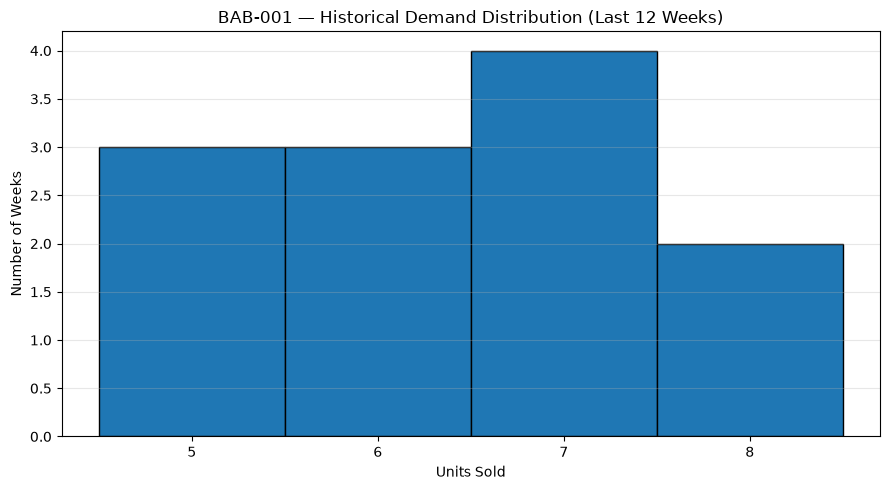

Historical demand distribution:
units_sold
5.0    3
6.0    3
7.0    4
8.0    2
Name: count, dtype: int64

Mean demand: 6.42
Median demand: 6.5
Minimum demand: 5.0
Maximum demand: 8.0


In [64]:
import matplotlib.pyplot as plt
import numpy as np

historical_demand = forecast_history["units_sold"].astype(float)

plt.figure(figsize=(9, 5))

plt.hist(
    historical_demand,
    bins=np.arange(
        historical_demand.min() - 0.5,
        historical_demand.max() + 1.5,
        1
    ),
    edgecolor="black"
)

plt.title("BAB-001 — Historical Demand Distribution (Last 12 Weeks)")
plt.xlabel("Units Sold")
plt.ylabel("Number of Weeks")
plt.xticks(range(
    int(historical_demand.min()),
    int(historical_demand.max()) + 1
))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Historical demand distribution:")
print(historical_demand.value_counts().sort_index())

print("\nMean demand:", round(historical_demand.mean(), 2))
print("Median demand:", round(historical_demand.median(), 2))
print("Minimum demand:", historical_demand.min())
print("Maximum demand:", historical_demand.max())

Compare Forecast with Recent Historical Demand
1. Markdown theory
This visualization compares the TFT forecast with the last 12 weeks of actual demand.

We will display:
- Actual demand for the last 12 weeks.
- TFT forecast for the next dataset week.
- Average demand across those 12 historical weeks.
- A boundary separating historical demand from the forecast.
This helps us understand whether the forecast is close to the recent demand pattern or unusually high or low.

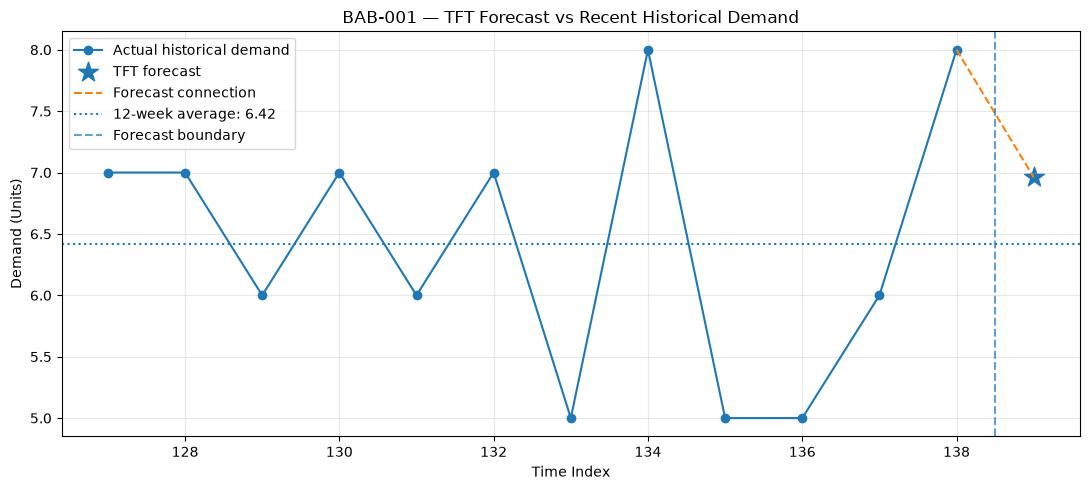

12-week historical average: 6.417
Last actual demand: 8.0
TFT forecast: 6.961
Forecast difference from average: 0.544


In [65]:
import matplotlib.pyplot as plt
import numpy as np

historical = forecast_history.sort_values("time_idx").copy()

history_x = historical["time_idx"].to_numpy()
history_y = historical["units_sold"].astype(float).to_numpy()

forecast_x = int(forecast_index["time_idx"].iloc[0])
forecast_y = float(forecast_prediction[0])

historical_mean = history_y.mean()

plt.figure(figsize=(11, 5))

plt.plot(
    history_x,
    history_y,
    marker="o",
    label="Actual historical demand"
)

plt.scatter(
    forecast_x,
    forecast_y,
    marker="*",
    s=220,
    label="TFT forecast"
)

plt.plot(
    [history_x[-1], forecast_x],
    [history_y[-1], forecast_y],
    linestyle="--",
    label="Forecast connection"
)

plt.axhline(
    historical_mean,
    linestyle=":",
    label=f"12-week average: {historical_mean:.2f}"
)

plt.axvline(
    history_x[-1] + 0.5,
    linestyle="--",
    alpha=0.7,
    label="Forecast boundary"
)

plt.title("BAB-001 — TFT Forecast vs Recent Historical Demand")
plt.xlabel("Time Index")
plt.ylabel("Demand (Units)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("12-week historical average:", round(historical_mean, 3))
print("Last actual demand:", history_y[-1])
print("TFT forecast:", round(forecast_y, 3))
print("Forecast difference from average:", round(forecast_y - historical_mean, 3))

Final Forecast Summary Visualization
1. Markdown theory
Now we will compare four important values:
1. Historical mean — average demand over the last 12 weeks.
2. Historical median — middle demand value.
3. Last actual demand — demand in the latest recorded week.
4. TFT forecast — predicted demand for the next dataset week.
This chart gives us a quick summary of the forecast relative to recent demand.

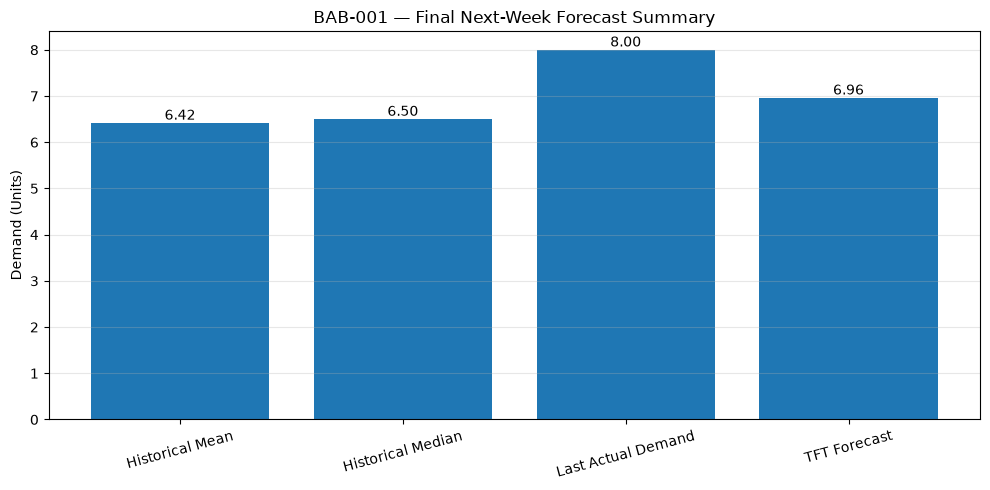

FINAL FORECAST SUMMARY
Historical Mean: 6.417
Historical Median: 6.500
Last Actual Demand: 8.000
TFT Forecast: 6.961

Forecast product: BAB-001
Forecast time index: 139
Forecast week: 2026-08-30


In [66]:
import matplotlib.pyplot as plt
import numpy as np

historical = forecast_history.sort_values("time_idx")
historical_demand = historical["units_sold"].astype(float)

summary_labels = [
    "Historical Mean",
    "Historical Median",
    "Last Actual Demand",
    "TFT Forecast"
]

summary_values = [
    historical_demand.mean(),
    historical_demand.median(),
    historical_demand.iloc[-1],
    float(forecast_prediction[0])
]

plt.figure(figsize=(10, 5))

bars = plt.bar(summary_labels, summary_values)

plt.title("BAB-001 — Final Next-Week Forecast Summary")
plt.ylabel("Demand (Units)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, summary_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

print("FINAL FORECAST SUMMARY")
for label, value in zip(summary_labels, summary_values):
    print(f"{label}: {value:.3f}")

print("\nForecast product: BAB-001")
print("Forecast time index:", forecast_x)
print("Forecast week: 2026-08-30")